# 🏭 Industry Project: Designing a Database End to End (Online Course Platform)

> **Who is this for?** A learner who has worked through the DBMS fundamentals notebooks (or knows basic SQL) and wants to
> see how a real database is designed **from a blank page to production**: the order of decisions, the checks at each step,
> and the trade-offs a senior engineer would explain in a design review or a system-design interview.
>
> **What you will learn**: requirements and business rules → ER diagram → relational mapping → FD check and BCNF →
> DDL with constraints and triggers → ~50k rows of realistic data → 10 business queries with window functions →
> indexes driven by `EXPLAIN QUERY PLAN` → safe transactions (enrolment + payment, rollback, idempotency) →
> data-quality tests → an ML feature table → migrations, backups and monitoring.
>
> **Prerequisites**: [`02_er_model_and_eer.ipynb`](./02_er_model_and_eer.ipynb), [`04_functional_dependencies_and_normalization.ipynb`](./04_functional_dependencies_and_normalization.ipynb), [`05_transactions_and_concurrency_control.ipynb`](./05_transactions_and_concurrency_control.ipynb), [`07_indexing_b_trees_and_hashing.ipynb`](./07_indexing_b_trees_and_hashing.ipynb) and SQL ([`../01_sql/01_sql_fundamentals.ipynb`](../01_sql/01_sql_fundamentals.ipynb)).
> The previous notebook, [`09_distributed_databases_warehousing_and_security.ipynb`](./09_distributed_databases_warehousing_and_security.ipynb),
> covers SQL injection and warehousing ideas used here.
>
> **Time needed**: about 2–3 hours to read and experiment (the notebook runs in well under a minute).
>
> **Runs on**: CPU, no API key, no server: SQLite (in a temporary folder, deleted at the end), pandas, numpy, matplotlib, networkx.
>
> **Optional track**: part of the **university-level fundamentals track**; recommended for BS/MS AI students and interview prep.

### How this notebook is different from the theory notebooks

| Theory notebooks (01–09) | This notebook |
|---|---|
| One concept at a time on 5–20 row tables | One **product**, every concept applied in the order a team would apply it |
| "Here is how normalisation works" | "Here is the founders' spreadsheet; prove the new schema is BCNF, lossless and dependency-preserving" |
| `CREATE TABLE` with a primary key | Constraints, composite foreign keys and triggers that make **business rules impossible to break** |
| Toy data | **~50,000 rows** with realistic distributions (popular courses, growth over time, drop-off) |
| "Indexes make queries faster" | Measure: read the query plan, add the index, re-measure; and see when an index cannot help |
| ACID in theory | An enrolment + payment transaction with a failing payment gateway, a race for the last coupon, and retries |
| — | Data-quality tests, an ML feature table, migrations, backups and monitoring |

### The business problem

**LearnLoop** is a 6-person startup selling online video courses. For its first year it ran on a Google Sheet and a no-code
payment page. The sheet now has thousands of rows, the same student appears with three spellings of their name, revenue
reports disagree with the payment provider, and an instructor was paid twice. You are the first data/backend engineer.
Your job: **design the production database**, prove it is correct, make the important queries fast, and hand the data team
a clean table for their first ML model (*"which new enrolments are at risk of never finishing?"*).

### Table of contents
1. [Setup](#1-setup)
2. [Requirements and business rules](#2-requirements-and-business-rules)
3. [Conceptual design: the ER diagram](#3-conceptual-design-the-er-diagram)
4. [Logical design: mapping the ER diagram to relations](#4-logical-design-mapping-the-er-diagram-to-relations)
5. [Functional dependencies and normalisation (BCNF)](#5-functional-dependencies-and-normalisation-bcnf))
6. [Physical design: DDL with constraints](#6-physical-design-ddl-with-constraints)
7. [Realistic synthetic data](#7-realistic-synthetic-data)
8. [Ten business queries](#8-ten-business-queries)
9. [Indexes driven by EXPLAIN QUERY PLAN](#9-indexes-driven-by-explain-query-plan)
10. [Transactions: enrolment and payment](#10-transactions-enrolment-and-payment)
11. [Data-quality tests](#11-data-quality-tests)
12. [A denormalised feature table for ML](#12-a-denormalised-feature-table-for-ml)
13. [Production operations: migrations, backups, monitoring](#13-production-operations-migrations-backups-monitoring)
14. [Summary, practice problems, further reading](#14-summary)

## Explained simply

Designing a database is like designing the filing system for a new school **before** the first day: you decide which forms
exist (students, classes, fees), what goes on each form, how the forms point to each other, and which rules may **never**
be broken (a student cannot be in the same class twice). Then you write those rules into the database itself, so that no
mistake, bug or careless script can break them. After that you fill it with realistic test data, check that the important
questions are answered quickly, make sure money operations happen completely or not at all, and plan how to change,
back up and watch the database once real users arrive. This notebook does all of those steps, in order, for a small
online-course company.

**Everyday examples**
- A restaurant's order system must not accept an order for a dish that is not on the menu: that is a **foreign key**.
- A bus-ticket website must never sell seat 14 twice, even if two people click "buy" at the same moment: that is a
  **unique constraint plus a transaction**.
- A shop coupon "valid for the first 100 customers" must stop at exactly 100: that is a **check done atomically**.

**A tiny example.** Sara buys the course "SQL 101" (price $20) with a 50%-off coupon. Three things must happen together:
a $10 payment is recorded, Sara's enrolment is created, and the coupon's "times used" goes from 4 to 5. If her card is
declined, **none** of the three may happen, otherwise Sara would get the course for free or the coupon would be used up for
nothing. Making these three changes "all or nothing" is what a **transaction** does.

| In one line | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| Business rule | a sentence the data must always obey | "one review per student per course", "seat 14 sold once" |
| Transaction | several changes that happen all together or not at all | paying and getting your ticket; saving training data with its labels |
| Index | the book-index of a table, so you find rows without reading every page | instant search in apps; fast feature lookups for ML models |

---
## 1. Setup

> **In plain English:** load the tools and create an empty database file in a temporary folder.

We use a **file-based** SQLite database in a temporary folder (not `:memory:`) because Sections 10 and 13 need real files:
a second connection that competes for a lock, and a backup file to restore from. In production you would use PostgreSQL or
MySQL; everything here is written so that it transfers, and the differences are pointed out where they matter.

In [1]:
import itertools                     # subsets for the FD algorithms
import os
import shutil
import sqlite3
import statistics
import tempfile
import time
from collections import defaultdict
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from matplotlib.patches import FancyBboxPatch, Polygon, Rectangle

pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 20)


@dataclass(frozen=True)
class Config:
    seed: int = 7
    n_users: int = 4_000
    n_instructors: int = 100
    n_courses: int = 250
    n_enrollments: int = 6_000
    start: str = "2025-01-01"
    end: str = "2026-09-30 23:59:59"        # the "today" of our database


CFG = Config()
rng = np.random.default_rng(CFG.seed)
WORKDIR = Path(tempfile.mkdtemp(prefix="learnloop_"))
DB_PATH = WORKDIR / "learnloop.db"
# isolation_level=None = autocommit mode: WE decide where transactions begin and end (BEGIN ... COMMIT)
conn = sqlite3.connect(DB_PATH, isolation_level=None)
conn.execute("pragma foreign_keys = on")     # SQLite enforces foreign keys only when this is ON (per connection!)
conn.execute("pragma journal_mode = wal")    # write-ahead log: readers do not block the writer
print("SQLite", sqlite3.sqlite_version, "| foreign keys:", conn.execute("pragma foreign_keys").fetchone()[0])


def sql(query, params=()):
    """Run a query and return a DataFrame (parameters are passed safely, never formatted into the text)."""
    return pd.read_sql_query(query, conn, params=params)

SQLite 3.45.1 | foreign keys: 1


---
## 2. Requirements and business rules

> **In plain English:** before any table, write down in plain sentences what the system must do and which rules can never be broken.

A database design starts with **interviews**, not with `CREATE TABLE`. The output is a list of requirements and, most
importantly, **business rules** written as precise, testable sentences. Each rule is later enforced somewhere (a key,
a constraint, a trigger, the application, or a test), and we keep track of where.

**Functional requirements** (what the system must do)
- FR1 Visitors sign up with an email; any user can become an instructor.
- FR2 Instructors create courses (draft → published → archived) made of ordered lessons.
- FR3 Students enrol in published courses; paid courses require a successful payment; coupons give discounts.
- FR4 Students mark lessons complete; the platform shows progress and completion.
- FR5 Students who enrolled can leave one review per course.
- FR6 Finance pays instructors 70% of net revenue monthly; management wants revenue, completion and cohort reports.
- FR7 The data team needs a feature table for a completion-risk model.

**Non-functional requirements**: ~5k users and ~10k enrolments in year one, growing 5–10× per year; read-heavy
(course pages, dashboards); money must never be wrong; personal data handled under GDPR-style rules; daily backups with
at most 24 h of data loss accepted at first (RPO), restore within 4 h (RTO).

**Business rules** and where each will be enforced:

| ID | Rule | Enforced by |
|---|---|---|
| BR1 | Every user has exactly one email; emails are unique **case-insensitively** | `UNIQUE` + `COLLATE NOCASE` |
| BR2 | An instructor is a user (1:1, optional) with a revenue share between 0 and 100% (default 70) | PK = FK, `CHECK` |
| BR3 | A course has exactly one instructor and one category | `NOT NULL` foreign keys |
| BR4 | A course's lessons are numbered 1, 2, 3, ... within the course | weak entity: PK `(course_id, lesson_no)` |
| BR5 | Only **published** courses accept enrolments, and only after their publish date | trigger |
| BR6 | A student enrols in a course **at most once** | `UNIQUE (user_id, course_id)` |
| BR7 | Price paid = list price minus the coupon discount; a paid enrolment needs a succeeded payment by the same user for exactly that amount | trigger |
| BR8 | A coupon has a validity window and a redemption limit that must never be exceeded | `CHECK` + atomic update in the transaction |
| BR9 | Instructors cannot enrol in their own course | trigger |
| BR10 | Lesson progress exists only for lessons of a course the student is enrolled in | **composite foreign keys** |
| BR11 | One review per enrolment, rating 1–5, only by enrolled students | FK to `enrollments` + `UNIQUE` + `CHECK` |
| BR12 | Payments are never updated or deleted (refunds are separate records) | triggers |
| BR13 | Money is stored as integer **cents**, never as floating point | `INTEGER` columns + `CHECK` |

> ⚠️ **Common mistake.** Skipping the business rules and going straight to tables. Rules like BR7 and BR10 decide the shape of
> the schema (composite keys, where foreign keys point); discovering them after launch means a painful migration.

---
## 3. Conceptual design: the ER diagram

> **In plain English:** draw the things (boxes) and how they are connected (diamonds and lines), and check the picture with the business people.

From the nouns and verbs of the requirements: **entities** (USER, INSTRUCTOR, COURSE, CATEGORY, LESSON, ENROLLMENT, PAYMENT,
COUPON, REVIEW) and **relationships** (teaches, enrols, completes, ...). Notation (Chen style, as in [`02_er_model_and_eer.ipynb`](./02_er_model_and_eer.ipynb)):
rectangles = entities, **double rectangle** = weak entity, diamonds = relationships (**double diamond** = identifying
relationship), the numbers on the lines are the cardinality ratios.

Two modelling decisions worth defending in a review:
- **ENROLLMENT is an associative entity**, not just an M:N relationship between USER and COURSE, because other things refer to it
  (payment, review, lesson progress). Giving it an identity makes those references simple.
- **LESSON is a weak entity**: "lesson 3" means nothing without its course, so its key is `(course_id, lesson_no)`.

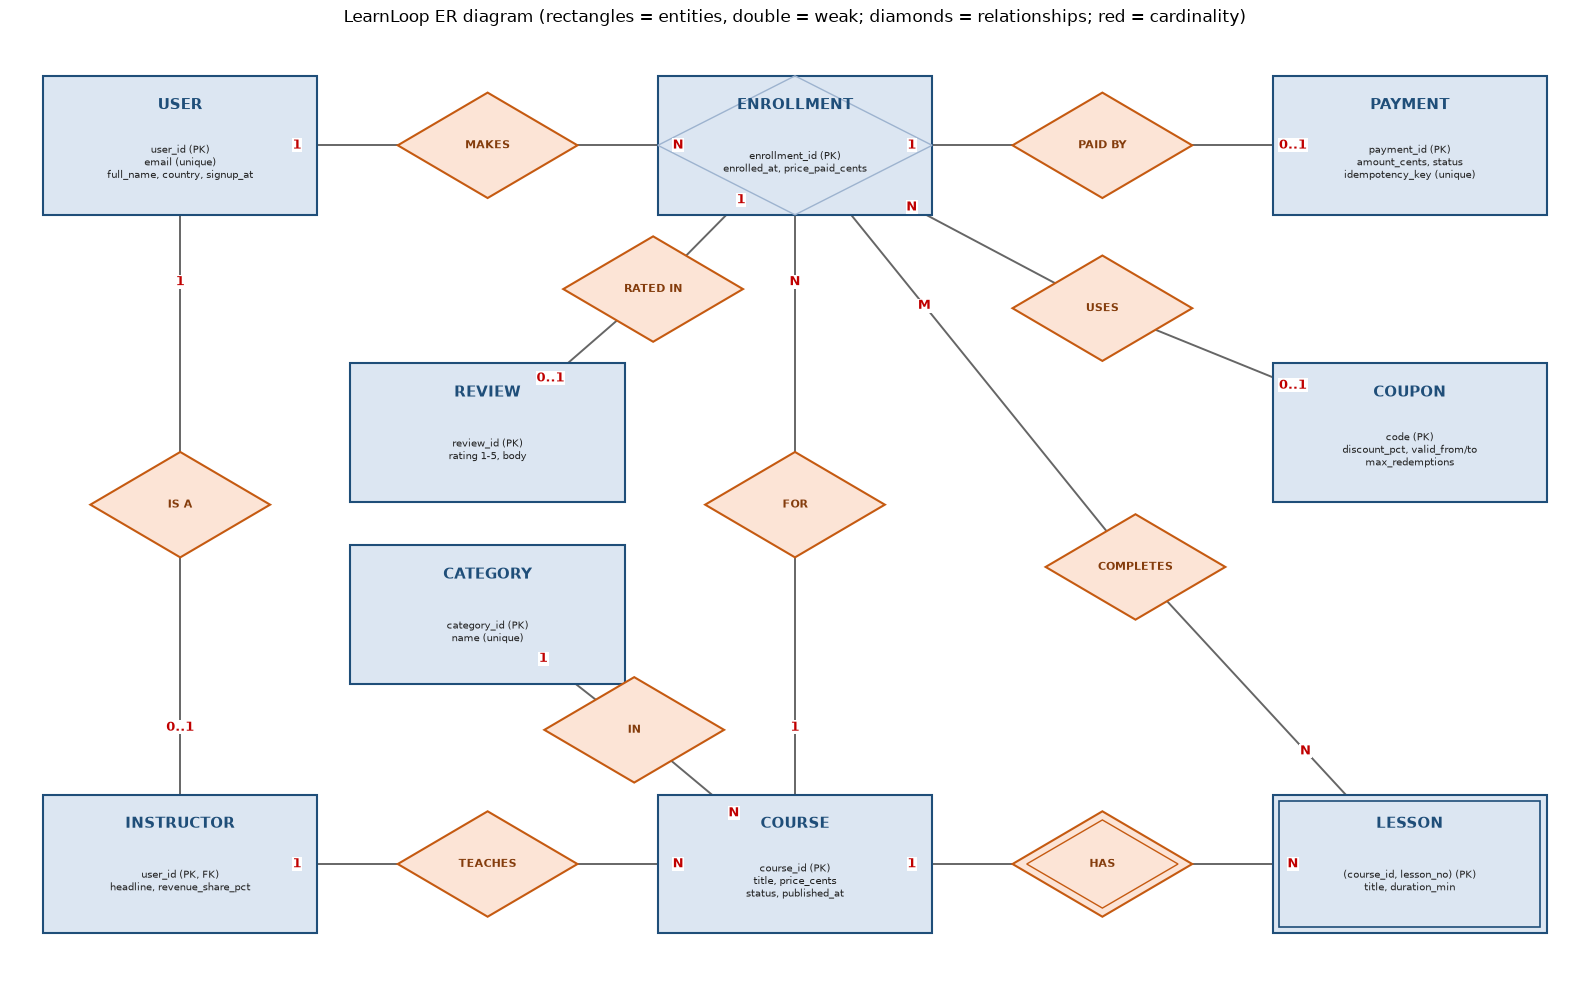

ER graph: 9 entities, 10 relationships, 20 lines


In [2]:
# Positions (x, y) of every entity / relationship on the canvas
entities = {   # name: (x, y, kind, key attributes shown in the box)
    "USER":       (1.5, 9.0, "strong", "user_id (PK)\nemail (unique)\nfull_name, country, signup_at"),
    "INSTRUCTOR": (1.5, 1.5, "strong", "user_id (PK, FK)\nheadline, revenue_share_pct"),
    "ENROLLMENT": (8.0, 9.0, "assoc",  "enrollment_id (PK)\nenrolled_at, price_paid_cents"),
    "PAYMENT":    (14.5, 9.0, "strong", "payment_id (PK)\namount_cents, status\nidempotency_key (unique)"),
    "COUPON":     (14.5, 6.0, "strong", "code (PK)\ndiscount_pct, valid_from/to\nmax_redemptions"),
    "REVIEW":     (4.75, 6.0, "strong", "review_id (PK)\nrating 1-5, body"),
    "COURSE":     (8.0, 1.5, "strong", "course_id (PK)\ntitle, price_cents\nstatus, published_at"),
    "CATEGORY":   (4.75, 4.1, "strong", "category_id (PK)\nname (unique)"),
    "LESSON":     (14.5, 1.5, "weak",   "(course_id, lesson_no) (PK)\ntitle, duration_min"),
}
relationships = {  # name: (x, y, identifying?, [(entity, cardinality label at that entity's end), ...])
    "IS A":     (1.5, 5.25, False, [("USER", "1"), ("INSTRUCTOR", "0..1")]),
    "MAKES":    (4.75, 9.0, False, [("USER", "1"), ("ENROLLMENT", "N")]),
    "PAID BY":  (11.25, 9.0, False, [("ENROLLMENT", "1"), ("PAYMENT", "0..1")]),
    "USES":     (11.25, 7.3, False, [("ENROLLMENT", "N"), ("COUPON", "0..1")]),
    "RATED IN": (6.5, 7.5, False, [("ENROLLMENT", "1"), ("REVIEW", "0..1")]),
    "FOR":      (8.0, 5.25, False, [("ENROLLMENT", "N"), ("COURSE", "1")]),
    "TEACHES":  (4.75, 1.5, False, [("INSTRUCTOR", "1"), ("COURSE", "N")]),
    "IN":       (6.3, 2.9, False, [("COURSE", "N"), ("CATEGORY", "1")]),
    "HAS":      (11.25, 1.5, True, [("COURSE", "1"), ("LESSON", "N")]),
    "COMPLETES": (11.6, 4.6, False, [("ENROLLMENT", "M"), ("LESSON", "N")]),
}

g = nx.Graph()
pos = {}
for name, (x, y, *_ ) in entities.items():
    g.add_node(name); pos[name] = (x, y)
for name, (x, y, _, ends) in relationships.items():
    g.add_node(name); pos[name] = (x, y)
    for ent, _ in ends:
        g.add_edge(name, ent)

fig, ax = plt.subplots(figsize=(16, 10))
nx.draw_networkx_edges(g, pos, ax=ax, edge_color="#666666", width=1.4)
W, H = 2.9, 1.45
for name, (x, y, kind, attrs) in entities.items():
    ax.add_patch(FancyBboxPatch((x - W / 2, y - H / 2), W, H, boxstyle="square,pad=0", fc="#DCE6F2", ec="#1F4E79", lw=1.5))
    if kind == "weak":            # double border = weak entity
        ax.add_patch(Rectangle((x - W / 2 + 0.07, y - H / 2 + 0.07), W - 0.14, H - 0.14, fill=False, ec="#1F4E79", lw=1.2))
    if kind == "assoc":           # associative entity: a diamond drawn inside the rectangle
        ax.add_patch(Polygon([[x - W / 2, y], [x, y + H / 2], [x + W / 2, y], [x, y - H / 2]], fill=False, ec="#9DB3CF", lw=1))
    ax.text(x, y + 0.42, name, ha="center", va="center", fontsize=11, weight="bold", color="#1F4E79")
    ax.text(x, y - 0.18, attrs, ha="center", va="center", fontsize=7.5, color="#222222")
for name, (x, y, identifying, ends) in relationships.items():
    w, h = 0.95, 0.55
    ax.add_patch(Polygon([[x - w, y], [x, y + h], [x + w, y], [x, y - h]], fc="#FCE4D6", ec="#C55A11", lw=1.5))
    if identifying:               # double diamond = identifying relationship of a weak entity
        ax.add_patch(Polygon([[x - w + 0.15, y], [x, y + h - 0.09], [x + w - 0.15, y], [x, y - h + 0.09]], fill=False, ec="#C55A11"))
    ax.text(x, y, name, ha="center", va="center", fontsize=8, weight="bold", color="#843C0C")
    for ent, card in ends:        # cardinality label near the entity end of the line
        ex, ey = pos[ent]
        lx, ly = x + 0.62 * (ex - x), y + 0.62 * (ey - y)
        ax.text(lx, ly, card, fontsize=9, color="#C00000", weight="bold", ha="center", va="center",
                bbox=dict(fc="white", ec="none", pad=0.5))
ax.set_xlim(-0.3, 16.3); ax.set_ylim(0.3, 10.2); ax.axis("off")
ax.set_title("LearnLoop ER diagram (rectangles = entities, double = weak; diamonds = relationships; red = cardinality)",
             fontsize=12)
plt.tight_layout(); plt.show()
print("ER graph:", sum(1 for n in entities), "entities,", len(relationships), "relationships,", g.number_of_edges(), "lines")

**What just happened?** We drew the conceptual model: 9 entities and 10 relationships. Read some lines aloud as a check with
the business: *"a USER makes N ENROLLMENTs; each ENROLLMENT is FOR exactly 1 COURSE; a COURSE HAS N LESSONs which cannot exist
without it; an ENROLLMENT COMPLETES M:N LESSONs (with a completion time)."* If a product manager disagrees with any sentence,
the diagram (not yet the database) is what you fix.

> 🎓 **Interview tip.** In a system-design interview, say the **cardinalities and participation** out loud ("every course must
> have an instructor: total participation; a user may or may not be an instructor: partial") before drawing tables. It shows
> you are designing from rules, not from guesses.

---
## 4. Logical design: mapping the ER diagram to relations

> **In plain English:** turn every box and line of the picture into tables and columns, using a fixed set of rules.

The standard ER-to-relational mapping algorithm (Elmasri & Navathe, ch. 9), applied to LearnLoop:

| ER construct | Mapping rule | LearnLoop result |
|---|---|---|
| Strong entity | one table; its key becomes the primary key | `users`, `courses`, `categories`, `coupons`, `payments` |
| Weak entity | table whose PK = owner's key + partial key; FK to owner `ON DELETE CASCADE` | `lessons(course_id, lesson_no, ...)` |
| 1:1 (IS A, partial) | FK on the optional side, made the PK (shared primary key) | `instructors(user_id PK → users)` |
| 1:N | FK on the N side | `courses.instructor_id`, `courses.category_id`, `enrollments.user_id`, `enrollments.course_id` |
| Associative entity (M:N with attributes and its own relationships) | its own table with a surrogate key + `UNIQUE` on the M:N pair | `enrollments(enrollment_id, user_id, course_id, ...)` + `UNIQUE(user_id, course_id)` |
| 1:0..1 (PAID BY, RATED IN) | FK on the optional side with `UNIQUE` | `enrollments.payment_id UNIQUE`, `reviews.enrollment_id UNIQUE` |
| M:N with attributes (COMPLETES) | a table whose PK combines both sides | `lesson_progress(enrollment_id, lesson_no, completed_at)` |

The resulting relational schema (PK in **bold**, → = foreign key):

```
users           (**user_id**, email UNIQUE NOCASE, full_name, country, signup_at)
instructors     (**user_id** → users, headline, revenue_share_pct)
categories      (**category_id**, name UNIQUE)
courses         (**course_id**, instructor_id → instructors, category_id → categories, title, price_cents,
                 status, created_at, published_at)
lessons         (**course_id** → courses, **lesson_no**, title, duration_min)
coupons         (**code**, discount_pct, valid_from, valid_to, max_redemptions, redemptions)
payments        (**payment_id**, user_id → users, amount_cents, currency, status, idempotency_key UNIQUE, created_at)
enrollments     (**enrollment_id**, user_id → users, course_id → courses, enrolled_at, price_paid_cents,
                 coupon_code → coupons, payment_id UNIQUE → payments;  UNIQUE(user_id, course_id))
lesson_progress (**enrollment_id**, **lesson_no**, course_id, completed_at;
                 (enrollment_id, course_id) → enrollments,  (course_id, lesson_no) → lessons)
reviews         (**review_id**, enrollment_id UNIQUE → enrollments, rating, body, created_at)
```

The interesting line is `lesson_progress`: it carries `course_id` **twice in two foreign keys**. The first says "this enrolment
is for course X", the second says "lesson n belongs to course X". Because both use the same `course_id` value, the database
itself guarantees BR10: you cannot record progress on a lesson of a course you are not enrolled in. No trigger needed.

---
## 5. Functional dependencies and normalisation (BCNF)

> **In plain English:** find the hidden repetition in the founders' spreadsheet and split it into tables where each fact is stored once.

The founders' Google Sheet had one row per enrolment with everything in it:

`ENROLL_SHEET(student_id, student_email, student_name, course_id, course_title, category, price, instructor_id,
instructor_name, enrolled_at, coupon_code, discount_pct, amount_paid)`

The business rules give these **functional dependencies** (FDs), $X \to Y$ meaning "$X$ determines $Y$":

| FD | Why (business rule) |
|---|---|
| student_id → student_email, student_name | a student has one email and name |
| student_email → student_id | emails are unique (BR1) |
| course_id → course_title, category, price, instructor_id | one instructor and category per course (BR3) |
| instructor_id → instructor_name | |
| coupon_code → discount_pct | |
| student_id, course_id → enrolled_at, coupon_code, amount_paid | one enrolment per student per course (BR6) |

The sheet suffered exactly the anomalies normalisation predicts: the **update anomaly** (a renamed course had to be fixed in
hundreds of rows, some were missed), the **insertion anomaly** (a new course with no students could not be listed), and the
**deletion anomaly** (deleting the only enrolment of a course lost the course). Below, a compact version of the algorithms
from [`04_functional_dependencies_and_normalization.ipynb`](./04_functional_dependencies_and_normalization.ipynb): attribute closure, candidate keys, BCNF check and decomposition, and the
lossless-join (chase) and dependency-preservation tests.

In [3]:
def fd(lhs, rhs):
    """Helper: build an FD from space-separated attribute names."""
    return (frozenset(lhs.split()), frozenset(rhs.split()))


R_SHEET = frozenset("""student_id student_email student_name course_id course_title category price instructor_id
                       instructor_name enrolled_at coupon_code discount_pct amount_paid""".split())
FDS = [fd("student_id", "student_email student_name"),
       fd("student_email", "student_id"),
       fd("course_id", "course_title category price instructor_id"),
       fd("instructor_id", "instructor_name"),
       fd("coupon_code", "discount_pct"),
       fd("student_id course_id", "enrolled_at coupon_code amount_paid")]


def closure(attrs, fds):
    """X+ : every attribute determined by X (repeat: if LHS ⊆ result, add RHS)."""
    result, changed = set(attrs), True
    while changed:
        changed = False
        for lhs, rhs in fds:
            if lhs <= result and not rhs <= result:
                result |= rhs; changed = True
    return frozenset(result)


def candidate_keys(R, fds):
    """Minimal superkeys. Attributes on no right-hand side must be in every key; we only search over the rest."""
    on_rhs = set().union(*(r for _, r in fds))
    core = R - on_rhs                                   # never determined by anything -> in every key
    optional = sorted(R & on_rhs)
    keys = []
    for k in range(len(optional) + 1):                  # smallest sets first, so the keys found are minimal
        for extra in itertools.combinations(optional, k):
            cand = core | set(extra)
            if closure(cand, fds) >= R and not any(key <= cand for key in keys):
                keys.append(frozenset(cand))
    return keys


def candidate_keys_brute_force(R, fds):
    """Check by trying all 2^|R| subsets."""
    supers = [frozenset(s) for k in range(1, len(R) + 1) for s in itertools.combinations(sorted(R), k)
              if closure(s, fds) >= R]
    return [s for s in supers if not any(t < s for t in supers)]


keys = candidate_keys(R_SHEET, FDS)
print("Candidate keys:", [sorted(k) for k in keys])
assert set(keys) == set(candidate_keys_brute_force(R_SHEET, FDS))
prime = set().union(*keys)
print("student_id+ =", sorted(closure({"student_id"}, FDS)))

# Which FDs violate 2NF / 3NF / BCNF in the sheet?
rows = []
for lhs, rhs in FDS:
    superkey = closure(lhs, FDS) >= R_SHEET
    nonprime_rhs = rhs - prime
    partial = any(lhs < k for k in keys) and bool(nonprime_rhs)       # part of a key -> non-prime attribute
    rows.append({"FD": f"{', '.join(sorted(lhs))} -> {', '.join(sorted(rhs))}", "LHS superkey?": superkey,
                 "violates BCNF": not superkey, "violates 3NF": (not superkey) and bool(nonprime_rhs),
                 "partial dependency (violates 2NF)": partial})
print(pd.DataFrame(rows).to_string(index=False))

Candidate keys: [['course_id', 'student_email'], ['course_id', 'student_id']]


student_id+ = ['student_email', 'student_id', 'student_name']
                                                            FD  LHS superkey?  violates BCNF  violates 3NF  partial dependency (violates 2NF)
                     student_id -> student_email, student_name          False           True          True                               True
                                   student_email -> student_id          False           True         False                              False
     course_id -> category, course_title, instructor_id, price          False           True          True                               True
                              instructor_id -> instructor_name          False           True          True                              False
                                   coupon_code -> discount_pct          False           True          True                              False
course_id, student_id -> amount_paid, coupon_code, enrolled_at           True         

In [4]:
def bcnf_violation(Ri, fds):
    """Return (X, Y) with X -> Y holding in Ri, Y not in X, X not a superkey of Ri; or None if Ri is in BCNF.
    Tries the given FDs' left sides first (gives natural tables), then every subset of Ri (complete check)."""
    subsets = [frozenset(s) for k in range(1, len(Ri)) for s in itertools.combinations(sorted(Ri), k)]
    for X in [l for l, _ in fds if l <= Ri] + subsets:
        Xp = closure(X, fds)
        Y = (Xp & Ri) - X
        if Y and not Xp >= Ri:
            return X, Y
    return None


def bcnf_decompose(R, fds):
    """Textbook BCNF decomposition: split Ri on a violating X -> Y into (X ∪ Y) and (Ri − Y)."""
    result, todo = [], [frozenset(R)]
    while todo:
        Ri = todo.pop()
        v = bcnf_violation(Ri, fds)
        if v is None:
            result.append(Ri)
        else:
            X, Y = v
            todo += [X | Y, Ri - Y]
    return result


def is_lossless(R, parts, fds):
    """Chase test: a tableau row per part; equate symbols using the FDs; lossless iff some row becomes all 'a'."""
    attrs = sorted(R)
    table = [{a: ("a" if a in p else f"b{i}") for a in attrs} for i, p in enumerate(parts)]
    changed = True
    while changed:
        changed = False
        for lhs, rhs in fds:
            groups = defaultdict(list)
            for row in table:
                groups[tuple(row[a] for a in sorted(lhs))].append(row)
            for rows_ in groups.values():
                for a in rhs:
                    vals = {r[a] for r in rows_}
                    target = "a" if "a" in vals else min(vals)
                    for r in rows_:
                        if r[a] != target:
                            r[a] = target; changed = True
    return any(all(v == "a" for v in row.values()) for row in table)


def preserves_dependencies(parts, fds):
    """Each FD X -> Y must follow from the FDs that hold inside the parts (algorithm without computing F+)."""
    for X, Y in fds:
        Z, changed = set(X), True
        while changed:
            changed = False
            for p in parts:
                add = (closure(Z & p, fds) & p) - Z
                if add:
                    Z |= add; changed = True
        if not Y <= Z:
            return False
    return True


parts = bcnf_decompose(R_SHEET, FDS)
for p in sorted(parts, key=len):
    print(f"{len(p):>2} attrs | BCNF: {bcnf_violation(p, FDS) is None} | key(s): "
          f"{[sorted(k) for k in candidate_keys(p, [(l, r & p) for l, r in FDS if l <= p])]} | {sorted(p)}")
print("lossless join:", is_lossless(R_SHEET, parts, FDS), "| dependency preserving:", preserves_dependencies(parts, FDS))
assert all(bcnf_violation(p, FDS) is None for p in parts)
assert is_lossless(R_SHEET, parts, FDS) and preserves_dependencies(parts, FDS)
assert bcnf_violation(R_SHEET, FDS) is not None                     # the sheet itself is NOT in BCNF

# Classic counter-example: BCNF can lose a dependency (street, city -> zip; zip -> city)
R_ADDR, F_ADDR = frozenset({"street", "city", "zip"}), [fd("street city", "zip"), fd("zip", "city")]
addr_parts = bcnf_decompose(R_ADDR, F_ADDR)
print("\naddress example:", [sorted(p) for p in addr_parts], "| lossless:", is_lossless(R_ADDR, addr_parts, F_ADDR),
      "| preserves street,city->zip:", preserves_dependencies(addr_parts, F_ADDR))
assert is_lossless(R_ADDR, addr_parts, F_ADDR) and not preserves_dependencies(addr_parts, F_ADDR)

 2 attrs | BCNF: True | key(s): [['coupon_code']] | ['coupon_code', 'discount_pct']
 2 attrs | BCNF: True | key(s): [['instructor_id']] | ['instructor_id', 'instructor_name']
 3 attrs | BCNF: True | key(s): [['student_email'], ['student_id']] | ['student_email', 'student_id', 'student_name']
 5 attrs | BCNF: True | key(s): [['course_id', 'student_id']] | ['amount_paid', 'coupon_code', 'course_id', 'enrolled_at', 'student_id']
 5 attrs | BCNF: True | key(s): [['course_id']] | ['category', 'course_id', 'course_title', 'instructor_id', 'price']
lossless join: True | dependency preserving: True

address example: [['street', 'zip'], ['city', 'zip']] | lossless: True | preserves street,city->zip: False


**What just happened?**
- The sheet has two candidate keys, `{student_id, course_id}` and `{student_email, course_id}` (the fast search agrees with a
  brute force over all $2^{13}$ subsets). Every FD except the last violates BCNF; the student, course and coupon FDs are
  **partial dependencies** (2NF violations) and `instructor_id → instructor_name` is **transitive** (3NF violation).
  `student_email → student_id` violates BCNF but not 3NF, because `student_id` is a **prime** attribute.
- BCNF decomposition produced five tables: students, courses, instructors, coupons and the enrolment table, exactly the
  `users`, `courses`, `instructors`, `coupons` and `enrollments` of Section 4. The ER design and the FD analysis agree, which is
  the check we wanted.
- The **chase** proves the decomposition is **lossless** (joining the tables gives back exactly the sheet, no spurious rows), and
  every FD is still checkable inside one table (**dependency preserving**).
- The address example shows why this is not automatic: BCNF can be lossless yet lose a dependency; then you choose between
  BCNF and **3NF synthesis**, which always preserves dependencies.

`category` became its own `categories` table even though normalisation did not require it: a lookup table with a foreign key
stops typos like "Data Sceince" and lets you rename a category in one place. That is a design choice, not a normal-form rule.

**Complexity.** Closure is $O(|F| \cdot |R|)$ per pass and at most $|R|$ passes. Candidate-key search and the BCNF check are
exponential in the worst case (there can be exponentially many keys), which is fine for the 10–20 attributes of a real table.

---
## 6. Physical design: DDL with constraints

> **In plain English:** write the CREATE TABLE statements, with every business rule built in, and prove each rule by trying to break it.

Design principles applied below:
- **`STRICT` tables** (SQLite ≥ 3.37): a column declared `INTEGER` rejects text. (By default SQLite would store `'abc'` in an
  integer column; PostgreSQL is always strict.)
- **Dates as ISO-8601 text** `YYYY-MM-DD HH:MM:SS` (SQLite has no date type), with a `CHECK` that the value round-trips through
  `strftime`, so malformed dates cannot enter. In PostgreSQL use `timestamptz`.
- **Money in integer cents** (BR13). Floating point cannot represent 0.10 exactly; `numeric(12,2)` is the PostgreSQL alternative.
- **Every business rule** from Section 2 maps to a constraint or a trigger; the names (`BR5`, ...) appear in the error messages
  so a developer who triggers one knows which rule they broke.
- Referential actions chosen deliberately: deleting a course **cascades** to its lessons (weak entity), but users, courses and
  payments are **restricted** (you never silently delete money or learning history).

In [5]:
# ISO format guard, reused below. `IS` (not `=`) matters: strftime() returns NULL for garbage, and a CHECK whose
# result is NULL counts as PASSED, so `x = strftime(...)` would let '01/03/2025' in.
DATE_OK = "check ({col} is strftime('%Y-%m-%d %H:%M:%S', {col}))"

SCHEMA_V1 = f"""
create table schema_migrations (version integer primary key, description text not null, applied_at text not null) strict;

create table users (
    user_id    integer primary key,
    email      text not null unique collate nocase check (email like '%_@_%._%'),          -- BR1
    full_name  text not null check (length(trim(full_name)) > 0),
    country    text not null check (length(country) = 2 and country = upper(country)),
    signup_at  text not null {DATE_OK.format(col="signup_at")}
) strict;

create table instructors (                                                                  -- BR2: IS-A, shared PK
    user_id           integer primary key references users(user_id) on delete restrict,
    headline          text,
    revenue_share_pct integer not null default 70 check (revenue_share_pct between 0 and 100)
) strict;

create table categories (
    category_id integer primary key,
    name        text not null unique collate nocase
) strict;

create table courses (
    course_id     integer primary key,
    instructor_id integer not null references instructors(user_id) on delete restrict,     -- BR3
    category_id   integer not null references categories(category_id) on delete restrict,
    title         text not null,
    price_cents   integer not null check (price_cents >= 0),                                -- BR13
    status        text not null default 'draft' check (status in ('draft', 'published', 'archived')),
    created_at    text not null {DATE_OK.format(col="created_at")},
    published_at  text,
    check ((status = 'draft') = (published_at is null)),          -- drafts have no publish date, others must
    check (published_at is null or published_at >= created_at)
) strict;

create table lessons (                                                                       -- BR4: weak entity
    course_id    integer not null references courses(course_id) on delete cascade,
    lesson_no    integer not null check (lesson_no >= 1),
    title        text not null,
    duration_min integer not null check (duration_min between 1 and 300),
    primary key (course_id, lesson_no)
) strict;

create table coupons (                                                                       -- BR8
    code            text primary key check (code = upper(code) and length(code) between 4 and 20),
    discount_pct    integer not null check (discount_pct between 1 and 100),
    valid_from      text not null,
    valid_to        text not null,
    max_redemptions integer not null check (max_redemptions > 0),
    redemptions     integer not null default 0,
    check (valid_to > valid_from),
    check (redemptions between 0 and max_redemptions)
) strict;

create table payments (                                                                      -- BR12, BR13
    payment_id      integer primary key,
    user_id         integer not null references users(user_id) on delete restrict,
    amount_cents    integer not null check (amount_cents > 0),
    currency        text not null default 'USD' check (currency = 'USD'),
    status          text not null check (status in ('succeeded', 'failed')),
    idempotency_key text not null unique,                  -- the same request retried never charges twice
    created_at      text not null {DATE_OK.format(col="created_at")}
) strict;

create table enrollments (
    enrollment_id    integer primary key,
    user_id          integer not null references users(user_id) on delete restrict,
    course_id        integer not null references courses(course_id) on delete restrict,
    enrolled_at      text not null {DATE_OK.format(col="enrolled_at")},
    price_paid_cents integer not null check (price_paid_cents >= 0),
    coupon_code      text references coupons(code) on delete restrict,
    payment_id       integer unique references payments(payment_id) on delete restrict,
    unique (user_id, course_id),                            -- BR6
    unique (enrollment_id, course_id)                       -- target of the composite FK in lesson_progress
) strict;

create table lesson_progress (                                                               -- BR10
    enrollment_id integer not null,
    course_id     integer not null,
    lesson_no     integer not null,
    completed_at  text not null {DATE_OK.format(col="completed_at")},
    primary key (enrollment_id, lesson_no),
    foreign key (enrollment_id, course_id) references enrollments(enrollment_id, course_id) on delete cascade,
    foreign key (course_id, lesson_no) references lessons(course_id, lesson_no) on delete restrict
) strict;

create table reviews (                                                                       -- BR11
    review_id     integer primary key,
    enrollment_id integer not null unique references enrollments(enrollment_id) on delete cascade,
    rating        integer not null check (rating between 1 and 5),
    body          text,
    created_at    text not null {DATE_OK.format(col="created_at")}
) strict;

-- Rules that span several tables cannot be CHECK constraints: use triggers
create trigger trg_enrollment_rules before insert on enrollments
begin
    select raise(abort, 'BR5: course is not open for enrolment')
     where (select status from courses where course_id = new.course_id) is not 'published'
        or new.enrolled_at < (select published_at from courses where course_id = new.course_id);
    select raise(abort, 'BR9: instructors cannot enrol in their own course')
     where exists (select 1 from courses where course_id = new.course_id and instructor_id = new.user_id);
    select raise(abort, 'BR7: price paid must equal the list price minus the coupon discount')
     where new.price_paid_cents <> (select (c.price_cents * (100 - coalesce(cp.discount_pct, 0)) + 50) / 100
                                    from courses c left join coupons cp on cp.code = new.coupon_code
                                    where c.course_id = new.course_id);
    select raise(abort, 'BR7: paid enrolment needs a succeeded payment of that amount by the same user')
     where new.price_paid_cents > 0 and not exists (
           select 1 from payments p where p.payment_id = new.payment_id and p.status = 'succeeded'
              and p.amount_cents = new.price_paid_cents and p.user_id = new.user_id);
end;

create trigger trg_payments_no_update before update of user_id, amount_cents, status, created_at on payments
begin select raise(abort, 'BR12: payments are immutable'); end;

create trigger trg_payments_no_delete before delete on payments
begin select raise(abort, 'BR12: payments are immutable'); end;
"""

conn.executescript(SCHEMA_V1)
conn.execute("insert into schema_migrations values (1, 'baseline schema', '2026-09-30 00:00:00')")
tables = [r[0] for r in conn.execute("select name from sqlite_master where type = 'table' order by name")]
print("tables:", tables)
print("triggers:", [r[0] for r in conn.execute("select name from sqlite_master where type = 'trigger'")])

tables: ['categories', 'coupons', 'courses', 'enrollments', 'instructors', 'lesson_progress', 'lessons', 'payments', 'reviews', 'schema_migrations', 'users']
triggers: ['trg_enrollment_rules', 'trg_payments_no_update', 'trg_payments_no_delete']


Now we **test the constraints before loading any data**: for each rule, try to break it and expect the database to refuse.
A test that only checks the happy path would never notice a missing constraint.

In [6]:
# A tiny fixture: 2 users, 1 instructor, 1 category, 1 paid published course with 2 lessons, 1 draft course
conn.executescript("""
insert into users values (1, 'teacher@example.com', 'Tariq Teacher', 'PK', '2025-01-01 10:00:00'),
                         (2, 'student@example.com', 'Sana Student', 'PK', '2025-01-02 10:00:00'),
                         (3, 'third@example.com', 'Tahir Third', 'PK', '2025-01-03 10:00:00');
insert into instructors (user_id, headline) values (1, 'SQL for data scientists');
insert into categories values (1, 'Data Science');
insert into courses values (1, 1, 1, 'SQL 101', 1999, 'published', '2025-01-05 00:00:00', '2025-01-10 00:00:00'),
                           (2, 1, 1, 'SQL 201', 2999, 'draft', '2025-01-06 00:00:00', null),
                           (3, 1, 1, 'Free intro', 0, 'published', '2025-01-05 00:00:00', '2025-01-06 00:00:00');
insert into lessons values (1, 1, 'SELECT', 10), (1, 2, 'JOIN', 15);
insert into payments values (1, 2, 1999, 'USD', 'succeeded', 'fixture-pay-1', '2025-02-01 09:00:00');
insert into enrollments values (1, 2, 1, '2025-02-01 09:00:00', 1999, null, 1),
                               (2, 2, 3, '2025-02-01 10:00:00', 0, null, null);
""")

violations = {
    "BR1 duplicate email (other case)": "insert into users values (4, 'STUDENT@example.com', 'X', 'PK', '2025-03-01 00:00:00')",
    "BR1 malformed email":              "insert into users values (4, 'not-an-email', 'X', 'PK', '2025-03-01 00:00:00')",
    "STRICT: text in integer column":   "insert into lessons values (1, 'three', 'x', 5)",
    "Date format guard":                "insert into users values (4, 'x@example.com', 'X', 'PK', '01/03/2025')",
    "BR2 revenue share > 100":          "insert into instructors values (2, 'x', 120)",
    "BR3 course without instructor":    "insert into courses values (9, 99, 1, 'X', 0, 'published', '2025-01-01 00:00:00', '2025-01-02 00:00:00')",
    "Draft course with publish date":   "insert into courses values (9, 1, 1, 'X', 0, 'draft', '2025-01-01 00:00:00', '2025-01-02 00:00:00')",
    "BR4 lesson of unknown course":     "insert into lessons values (99, 1, 'x', 5)",
    "BR5 enrol in a draft course":      "insert into enrollments values (2, 2, 2, '2025-02-01 09:00:00', 0, null, null)",
    "BR6 enrol twice":                  "insert into enrollments values (3, 2, 3, '2025-03-01 09:00:00', 0, null, null)",
    "BR7 paid course for free":         "insert into enrollments (user_id, course_id, enrolled_at, price_paid_cents) values (3, 1, '2025-03-01 09:00:00', 0)",
    "BR7 paid course without payment":  "insert into enrollments (user_id, course_id, enrolled_at, price_paid_cents) values (3, 1, '2025-03-01 09:00:00', 1999)",
    "BR9 instructor in own course":     "insert into enrollments (user_id, course_id, enrolled_at, price_paid_cents) values (1, 3, '2025-03-01 09:00:00', 0)",
    "BR10 progress, lesson not in course": "insert into lesson_progress values (1, 1, 7, '2025-02-02 10:00:00')",
    "BR10 progress, wrong course":      "insert into lesson_progress values (1, 2, 1, '2025-02-02 10:00:00')",
    "BR11 rating 6":                    "insert into reviews values (1, 1, 6, 'wow', '2025-02-03 10:00:00')",
    "BR11 review without enrolment":    "insert into reviews values (1, 999, 5, 'x', '2025-02-03 10:00:00')",
    "BR12 change a payment amount":     "update payments set amount_cents = 1 where payment_id = 1",
    "BR12 delete a payment":            "delete from payments where payment_id = 1",
    "BR13 negative price":              "insert into courses values (9, 1, 1, 'X', -5, 'published', '2025-01-01 00:00:00', '2025-01-02 00:00:00')",
}
results = []
for rule, stmt in violations.items():
    try:
        conn.execute(stmt)
        results.append({"rule": rule, "result": "ACCEPTED (BUG!)", "error": ""})
    except sqlite3.DatabaseError as e:                 # IntegrityError for constraints and RAISE(ABORT)
        results.append({"rule": rule, "result": "rejected", "error": str(e)[:70]})
check_df = pd.DataFrame(results)
print(check_df.to_string(index=False))
assert (check_df.result == "rejected").all(), "a business rule is not enforced!"

# ...and for the RIGHT reason (a test that passes because of a different error proves nothing)
expected = {"BR5 enrol in a draft course": "BR5", "BR6 enrol twice": "UNIQUE", "BR7 paid course for free": "BR7",
            "BR7 paid course without payment": "BR7", "BR9 instructor in own course": "BR9",
            "Date format guard": "CHECK", "BR12 delete a payment": "BR12"}
for rule, tag in expected.items():
    assert tag in check_df.set_index("rule").loc[rule, "error"], rule

# Remove the fixture (payments are immutable, so drop the trigger temporarily, as a migration would)
conn.executescript("""
begin;
delete from enrollments; delete from lessons; delete from courses; delete from categories; delete from instructors;
drop trigger trg_payments_no_delete; delete from payments; delete from users;
create trigger trg_payments_no_delete before delete on payments begin select raise(abort, 'BR12: payments are immutable'); end;
commit;
""")
assert conn.execute("select count(*) from users").fetchone()[0] == 0

                               rule   result                                                                  error
   BR1 duplicate email (other case) rejected                                  UNIQUE constraint failed: users.email
                BR1 malformed email rejected                         CHECK constraint failed: email like '%_@_%._%'
     STRICT: text in integer column rejected            cannot store TEXT value in INTEGER column lessons.lesson_no
                  Date format guard rejected CHECK constraint failed: signup_at is strftime('%Y-%m-%d %H:%M:%S', si
            BR2 revenue share > 100 rejected           CHECK constraint failed: revenue_share_pct between 0 and 100
      BR3 course without instructor rejected                                          FOREIGN KEY constraint failed
     Draft course with publish date rejected   CHECK constraint failed: (status = 'draft') = (published_at is null)
       BR4 lesson of unknown course rejected                            

**What just happened?** Every one of the 20 attempts to break a rule was **rejected by the database**, with an error that
names the rule. This is the strongest guarantee you can get: no future bug in the application, no analyst with a SQL console,
and no buggy import script can create data that breaks these rules.

> ⚠️ **Common mistake.** Writing `CHECK (d = strftime(..., d))`. A `CHECK` fails only when its expression is
> **false**; if it evaluates to `NULL` (unknown), the row is **accepted**. `strftime()` returns `NULL` for garbage like
> `'01/03/2025'`, so the guard must use the NULL-safe `IS` comparison. The same three-valued logic bites in `WHERE` clauses.
>
> ⚠️ **Common mistake.** Forgetting `PRAGMA foreign_keys = ON` in SQLite. It is **off by default** and must be set on every new
> connection; otherwise every `REFERENCES` clause above is silently ignored. (PostgreSQL and MySQL/InnoDB always enforce
> foreign keys.)

---
## 7. Realistic synthetic data

> **In plain English:** fill the database with about 50,000 fake but realistic rows, so tests behave like real life.

We cannot use real student data (privacy), but a test database with uniform random data hides real problems: no popular
courses, no skew, no seasonality, no drop-off. The generator below builds a **plausible year and nine months** of LearnLoop:
- sign-ups **accelerate** over time (a growing startup);
- course popularity is **heavily skewed** (a few hits, a long tail), driven by a hidden "quality" score;
- prices come in tiers (free, $19.99, $29.99, $49.99, $89.99); ~15% of paid enrolments use a coupon, if one is valid and not used up;
- ~5% of payments fail once before succeeding (the failed attempts are kept, as real payment tables do);
- learners complete lessons in order; completion is more likely for paid, high-quality, shorter courses and motivated learners,
  and slower learners spread lessons out over time;
- about a third of learners who started a course leave a review, more positive for good courses they finished.

Every rule from Section 2 is respected, because the data is loaded **through all the constraints and triggers**.

In [7]:
START, END = pd.Timestamp(CFG.start), pd.Timestamp(CFG.end)
SPAN_S = (END - START).total_seconds()
fmt = lambda t: t.strftime("%Y-%m-%d %H:%M:%S")                     # Timestamp -> ISO text


def sigmoid(x):
    return 1 / (1 + np.exp(-x))


# ---------------- users: growth = more sign-ups later (beta distribution skewed to the right) ----------------
first = ["Ali", "Sara", "Omar", "Ayesha", "Bilal", "Hina", "Usman", "Zara", "Hamza", "Fatima", "John", "Maria",
         "Wei", "Priya", "Ahmed", "Chloe", "Diego", "Amina", "Yusuf", "Elena"]
last = ["Khan", "Ahmed", "Malik", "Raza", "Smith", "Garcia", "Chen", "Patel", "Hussain", "Okafor", "Rossi", "Silva"]
countries = ["PK", "IN", "US", "GB", "AE", "NG", "DE", "BR"]
signup = START + pd.to_timedelta(np.sort(rng.beta(1.6, 1.0, CFG.n_users)) * SPAN_S * 0.999, unit="s")
signup = signup.floor("s")
users = pd.DataFrame({"user_id": np.arange(1, CFG.n_users + 1),
                      "first": rng.choice(first, CFG.n_users), "last": rng.choice(last, CFG.n_users),
                      "country": rng.choice(countries, CFG.n_users, p=[.3, .2, .15, .1, .08, .07, .05, .05]),
                      "signup_at": signup})
users["full_name"] = users["first"] + " " + users["last"]
users["email"] = (users["first"] + "." + users["last"] + users.user_id.astype(str) + "@example.com").str.lower()
users["motivation"] = rng.normal(0, 1, CFG.n_users)                   # hidden trait, never stored in the DB

# ---------------- instructors: early users ----------------
instr_ids = np.sort(rng.choice(users.user_id[: CFG.n_users // 2], CFG.n_instructors, replace=False))
instructors = pd.DataFrame({"user_id": instr_ids, "headline": [f"Instructor #{i}" for i in range(CFG.n_instructors)],
                            "revenue_share_pct": 70})

# ---------------- categories and courses ----------------
cats = ["Data Science", "Machine Learning", "Web Development", "Databases", "Cloud", "Design", "Business", "Languages"]
categories = pd.DataFrame({"category_id": range(1, len(cats) + 1), "name": cats})
course_instr = rng.choice(instr_ids, CFG.n_courses)
instr_signup = users.set_index("user_id").signup_at
created = [min(instr_signup[i] + pd.Timedelta(days=float(rng.uniform(1, 120))), END - pd.Timedelta(days=60))
           for i in course_instr]
status = rng.choice(["published", "draft", "archived"], CFG.n_courses, p=[.88, .08, .04])
courses = pd.DataFrame({
    "course_id": np.arange(1, CFG.n_courses + 1), "instructor_id": course_instr,
    "category_id": rng.integers(1, len(cats) + 1, CFG.n_courses),
    "price_cents": rng.choice([0, 1999, 2999, 4999, 8999], CFG.n_courses, p=[.15, .25, .3, .2, .1]),
    "status": status, "created_at": pd.to_datetime(created).floor("s"),
    "quality": rng.normal(0, 1, CFG.n_courses),                       # hidden
    "n_lessons": rng.integers(4, 16, CFG.n_courses)})
courses["published_at"] = [c + pd.Timedelta(days=float(rng.uniform(1, 30))) if s != "draft" else pd.NaT
                           for c, s in zip(courses.created_at, courses.status)]
courses["published_at"] = pd.to_datetime(courses.published_at).dt.floor("s")
courses["title"] = [f"{cats[c - 1]} course {i}" for i, c in zip(courses.course_id, courses.category_id)]
lessons = pd.DataFrame([(c, n, f"Lesson {n}", int(rng.integers(5, 40)))
                        for c, k in zip(courses.course_id, courses.n_lessons) for n in range(1, k + 1)],
                       columns=["course_id", "lesson_no", "title", "duration_min"])

# ---------------- coupons ----------------
coupon_rows = []
for i in range(30):
    vf = START + pd.Timedelta(days=float(rng.uniform(0, 600)))
    coupon_rows.append((f"LOOP{i:02d}{rng.choice(['A', 'B', 'C'])}", int(rng.choice([10, 20, 25, 30, 50])), fmt(vf),
                        fmt(vf + pd.Timedelta(days=float(rng.integers(20, 90)))), int(rng.choice([20, 50, 100]))))
coupons = pd.DataFrame(coupon_rows, columns=["code", "discount_pct", "valid_from", "valid_to", "max_redemptions"])
print(len(users), "users,", len(instructors), "instructors,", len(courses), "courses,", len(lessons), "lessons,",
      len(coupons), "coupons")

4000 users, 100 instructors, 250 courses, 2427 lessons, 30 coupons


In [8]:
# Work in "seconds since START" (plain floats) inside the loops: much faster than pandas Timestamps one by one
secs = lambda ts: (pd.to_datetime(ts) - START).total_seconds() if np.isscalar(ts) else (pd.to_datetime(ts) - START).dt.total_seconds().values
to_text = lambda s: (START + pd.to_timedelta(np.floor(np.asarray(s, dtype=float)), unit="s")).strftime("%Y-%m-%d %H:%M:%S")
DAY = 86_400.0

# ---------------- enrollments: popular courses get most students ----------------
pub = courses[courses.status == "published"].reset_index(drop=True)
weights = np.exp(1.2 * pub.quality.values + rng.normal(0, 0.8, len(pub)))       # skewed popularity
weights /= weights.sum()
pub_id, pub_price = pub.course_id.values, pub.price_cents.values
pub_q, pub_n, pub_pub = pub.quality.values, pub.n_lessons.values, secs(pub.published_at)
user_signup = secs(users.signup_at)                                               # index = user_id - 1
owner = dict(zip(courses.course_id, courses.instructor_id))
END_S = SPAN_S
cand_c = rng.choice(len(pub), 4 * CFG.n_enrollments, p=weights)                  # draw candidates in one go
cand_u = rng.integers(1, CFG.n_users + 1, 4 * CFG.n_enrollments)
cand_gap = rng.exponential(20 * DAY, 4 * CFG.n_enrollments)                       # gap after sign-up / publication
seen, rows_ = set(), []
for ci, u, gap in zip(cand_c, cand_u, cand_gap):
    cid = int(pub_id[ci])
    if (u, cid) in seen or owner[cid] == u:
        continue                                                                  # BR6, BR9
    t = max(user_signup[u - 1], pub_pub[ci]) + gap
    if t > END_S:
        continue
    seen.add((u, cid))
    rows_.append((int(u), cid, np.floor(t), int(pub_price[ci]), pub_q[ci], int(pub_n[ci])))
    if len(rows_) == CFG.n_enrollments:
        break
enr = pd.DataFrame(rows_, columns=["user_id", "course_id", "t", "list_price", "quality", "n_lessons"])
enr = enr.sort_values("t", kind="stable").reset_index(drop=True)
enr["enrollment_id"] = np.arange(1, len(enr) + 1)                                # ids in time order, like a real system

# ---------------- coupons and payments, in time order (coupon limits must hold at every moment) ----------------
c_code, c_pct = coupons.code.tolist(), coupons.discount_pct.tolist()
c_from, c_to = secs(coupons.valid_from), secs(coupons.valid_to)
c_left = coupons.max_redemptions.tolist()
pays, codes, paid, pay_ids = [], [], [], []
for u, t, price in zip(enr.user_id, enr.t, enr.list_price):
    code = None
    if price > 0 and rng.random() < 0.15:
        valid = [k for k in range(len(c_code)) if c_from[k] <= t < c_to[k] and c_left[k] > 0]
        if valid:
            k = valid[int(rng.integers(len(valid)))]
            code, price = c_code[k], (price * (100 - c_pct[k]) + 50) // 100
            c_left[k] -= 1
    pay_id = None
    if price > 0:
        if rng.random() < 0.05:                                                   # a declined card first
            pays.append((u, price, "failed", f"pay_{len(pays):07d}", t - 180))
        pays.append((u, price, "succeeded", f"pay_{len(pays):07d}", t))
        pay_id = len(pays)                                                        # payment_id = row number
    codes.append(code); paid.append(int(price)); pay_ids.append(pay_id)
enr["coupon_code"], enr["price_paid_cents"], enr["payment_id"] = codes, paid, pay_ids
payments = pd.DataFrame(pays, columns=["user_id", "amount_cents", "status", "idempotency_key", "t"])
payments.insert(0, "payment_id", np.arange(1, len(payments) + 1))

# ---------------- lesson progress ----------------
motivation = users.motivation.values                                             # index = user_id - 1
prior = enr.groupby("user_id").cumcount().values                                 # enrolments before this one
p_all = sigmoid(-1.3 + 0.7 * (enr.price_paid_cents.values > 0) + 0.6 * enr.quality.values
                - 0.12 * (enr.n_lessons.values - 9) + 0.7 * motivation[enr.user_id.values - 1] + 0.15 * prior)
prog = []
for eid, cid, n, t, p in zip(enr.enrollment_id, enr.course_id, enr.n_lessons, enr.t, p_all):
    engaged = rng.random() < p
    n_done = n if engaged else min(int(rng.geometric(0.35)) - 1, n - 1)        # drop-outs stop early
    gap = 1.5 * DAY if engaged else 6.0 * DAY
    for lesson in range(1, n_done + 1):
        t = t + rng.exponential(gap) + 600
        if t > END_S:
            break
        prog.append((eid, cid, lesson, np.floor(t)))
progress = pd.DataFrame(prog, columns=["enrollment_id", "course_id", "lesson_no", "t"])

# ---------------- reviews ----------------
agg = progress.groupby("enrollment_id").agg(n=("lesson_no", "size"), last=("t", "max"))
n_done_map, last_map = agg.n.to_dict(), agg["last"].to_dict()
rev = []
for eid, n_lessons, q in zip(enr.enrollment_id, enr.n_lessons, enr.quality):
    if eid in n_done_map and rng.random() < 0.35:
        finished = n_done_map[eid] == n_lessons
        rating = int(np.clip(round(3.4 + 0.8 * q + 0.7 * finished + rng.normal(0, 0.8)), 1, 5))
        t = last_map[eid] + rng.uniform(1, 72) * 3600
        if t <= END_S:
            rev.append((eid, rating, None, np.floor(t)))
reviews = pd.DataFrame(rev, columns=["enrollment_id", "rating", "body", "t"])
reviews.insert(0, "review_id", np.arange(1, len(reviews) + 1))

# seconds -> ISO text, all at once
enr["enrolled_at"] = pd.to_datetime(to_text(enr.t))
payments["created_at"] = to_text(payments.t)
progress["completed_at"] = to_text(progress.t)
reviews["created_at"] = to_text(reviews.t)
print(len(enr), "enrollments,", len(payments), "payments,", len(progress), "lesson completions,", len(reviews), "reviews")

6000 enrollments, 5390 payments, 30940 lesson completions, 1654 reviews


In [9]:
def as_rows(df, cols):
    """DataFrame -> list of tuples with Python types; Timestamps become ISO text, NaN/NaT become NULL."""
    out = df[cols].copy()
    for c in cols:
        if pd.api.types.is_datetime64_any_dtype(out[c]):
            out[c] = out[c].map(lambda t: fmt(t) if pd.notna(t) else None)
    out = out.astype(object).where(out.notna(), None)
    def py(v):                                          # numpy / float ids -> plain Python int for sqlite
        if isinstance(v, (np.integer, float)) and float(v).is_integer():
            return int(v)
        return v
    return [tuple(py(v) for v in r) for r in out.itertuples(index=False)]


t0 = time.perf_counter()
conn.execute("begin")                                   # ONE transaction for the bulk load: much faster, all-or-nothing
loads = [
    ("users", users, ["user_id", "email", "full_name", "country", "signup_at"]),
    ("instructors", instructors, ["user_id", "headline", "revenue_share_pct"]),
    ("categories", categories, ["category_id", "name"]),
    ("courses", courses, ["course_id", "instructor_id", "category_id", "title", "price_cents", "status", "created_at", "published_at"]),
    ("lessons", lessons, ["course_id", "lesson_no", "title", "duration_min"]),
    ("coupons", coupons, ["code", "discount_pct", "valid_from", "valid_to", "max_redemptions"]),
    ("payments", payments, ["payment_id", "user_id", "amount_cents", "status", "idempotency_key", "created_at"]),
    ("enrollments", enr, ["enrollment_id", "user_id", "course_id", "enrolled_at", "price_paid_cents", "coupon_code", "payment_id"]),
    ("lesson_progress", progress, ["enrollment_id", "course_id", "lesson_no", "completed_at"]),
    ("reviews", reviews, ["review_id", "enrollment_id", "rating", "body", "created_at"]),
]
for table, df, cols in loads:
    conn.executemany(f"insert into {table} ({', '.join(cols)}) values ({', '.join('?' * len(cols))})", as_rows(df, cols))
# coupon redemption counters (denormalised counter, kept consistent by the enrolment transaction from now on)
conn.execute("""update coupons set redemptions = (select count(*) from enrollments e where e.coupon_code = coupons.code)""")
conn.execute("commit")
load_s = time.perf_counter() - t0

counts = {t: conn.execute(f"select count(*) from {t}").fetchone()[0] for t, _, _ in loads}
print(counts, "\nTOTAL rows:", sum(counts.values()), f"| loaded through all constraints + triggers in {load_s:.1f} s")
assert 45_000 <= sum(counts.values()) <= 70_000
assert conn.execute("pragma foreign_key_check").fetchall() == []

{'users': 4000, 'instructors': 100, 'categories': 8, 'courses': 250, 'lessons': 2427, 'coupons': 30, 'payments': 5390, 'enrollments': 6000, 'lesson_progress': 30940, 'reviews': 1654} 
TOTAL rows: 50799 | loaded through all constraints + triggers in 2.4 s


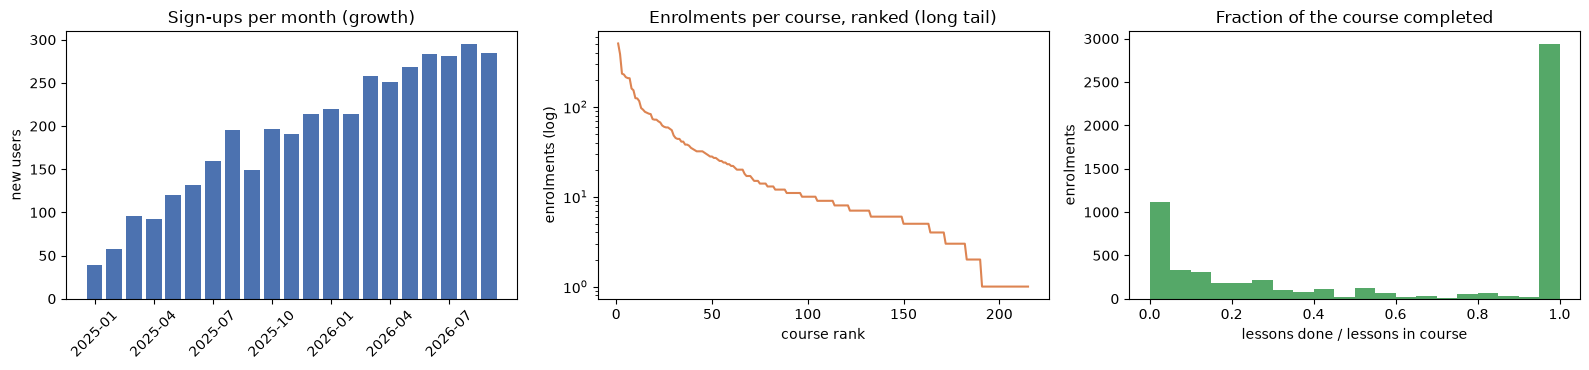

top 10 courses = 40% of all enrolments; fully completed: 49%; never started: 19%


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
monthly = sql("select substr(signup_at, 1, 7) m, count(*) n from users group by m")
axes[0].bar(monthly.m, monthly.n, color="#4C72B0"); axes[0].set_title("Sign-ups per month (growth)")
axes[0].set_xticks(monthly.m[::3]); axes[0].tick_params(axis="x", rotation=45); axes[0].set_ylabel("new users")
pop = sql("select course_id, count(*) n from enrollments group by course_id order by n desc")
axes[1].plot(np.arange(1, len(pop) + 1), pop.n, color="#DD8452"); axes[1].set_yscale("log")
axes[1].set_title("Enrolments per course, ranked (long tail)"); axes[1].set_xlabel("course rank"); axes[1].set_ylabel("enrolments (log)")
done = sql("""select e.enrollment_id, count(p.lesson_no) * 1.0 / (select count(*) from lessons l where l.course_id = e.course_id) frac
              from enrollments e left join lesson_progress p using (enrollment_id) group by e.enrollment_id""")
axes[2].hist(done.frac, bins=20, color="#55A868"); axes[2].set_title("Fraction of the course completed")
axes[2].set_xlabel("lessons done / lessons in course"); axes[2].set_ylabel("enrolments")
plt.tight_layout(); plt.show()
top10_share = pop.n.head(10).sum() / pop.n.sum()
print(f"top 10 courses = {top10_share:.0%} of all enrolments; fully completed: {(done.frac == 1).mean():.0%}; "
      f"never started: {(done.frac == 0).mean():.0%}")

**What just happened?** About 50k rows were loaded **inside one transaction** and every row passed every constraint and
trigger (the foreign-key check is empty). The plots show the shapes we wanted: accelerating sign-ups, a long tail of course
popularity (log scale), and the typical "U-shape" of online learning: many learners stop early or never start, a solid group
finishes everything.

> 🎓 **Interview tip.** "How would you test with realistic data?" Mention **skew** (hot keys break naive designs), **growth**
> (query plans change as tables grow) and **edge cases on purpose** (failed payments, used-up coupons, drafts).
> See also [`../../03_Machine_Learning/15_synthetic_tabular_data/02_industry_synthetic_test_data_for_development.ipynb`](../../03_Machine_Learning/15_synthetic_tabular_data/02_industry_synthetic_test_data_for_development.ipynb).

---
## 8. Ten business queries

> **In plain English:** answer the ten questions the team asks most, and double-check every answer another way.

Each query answers a real question from the team, is written as readable CTEs, and comes with an **assert** that cross-checks
it against a simpler computation. Window functions (`LAG`, `ROW_NUMBER`, `SUM() OVER`, `NTILE`, `PERCENT_RANK`, `LEAD`) do
most of the heavy lifting.

In [11]:
# Q1 (CEO): net revenue per month and month-over-month growth
q1 = sql("""
with monthly as (
    select substr(created_at, 1, 7) as month, sum(amount_cents) / 100.0 as revenue
    from payments where status = 'succeeded' group by month
)
select month, revenue,
       round(100.0 * (revenue - lag(revenue) over (order by month)) / lag(revenue) over (order by month), 1) as mom_growth_pct
from monthly order by month""")
print("Q1 monthly revenue (last 6 months):\n", q1.tail(6).to_string(index=False))
assert np.isclose(q1.revenue.sum(), payments.query("status == 'succeeded'").amount_cents.sum() / 100)

# Q2 (marketing): top 3 courses by revenue in every category
q2 = sql("""
with course_revenue as (
    select c.course_id, c.title, cat.name as category, count(*) as enrolments,
           sum(e.price_paid_cents) / 100.0 as revenue
    from enrollments e join courses c using (course_id) join categories cat using (category_id)
    group by c.course_id
), ranked as (
    select *, row_number() over (partition by category order by revenue desc, course_id) as rank_in_category
    from course_revenue
)
select category, rank_in_category, title, enrolments, revenue from ranked where rank_in_category <= 3
order by category, rank_in_category""")
print("\nQ2 top-3 courses per category (first 6 rows):\n", q2.head(6).to_string(index=False))
assert q2.groupby("category").size().max() == 3
assert (q2.groupby("category").revenue.apply(lambda s: s.is_monotonic_decreasing)).all()

Q1 monthly revenue (last 6 months):
   month  revenue  mom_growth_pct
2026-04 17554.60             7.6
2026-05 17831.29             1.6
2026-06 15223.03           -14.6
2026-07 15572.98             2.3
2026-08 13575.63           -12.8
2026-09 14021.61             3.3

Q2 top-3 courses per category (first 6 rows):
 category  rank_in_category               title  enrolments  revenue
Business                 1 Business course 195          37  1717.15
Business                 2 Business course 207          29  1417.21
Business                 3 Business course 169          41  1190.59
   Cloud                 1     Cloud course 92         229 11195.24
   Cloud                 2    Cloud course 172         116 10191.37
   Cloud                 3    Cloud course 112          84  4041.70


In [12]:
# Q3 (finance): instructor payouts for the last full month (September 2026), 70% revenue share
q3 = sql("""
select i.user_id as instructor_id, u.full_name, count(*) as paid_sales,
       sum(e.price_paid_cents) / 100.0 as gross,
       round(sum(e.price_paid_cents) * i.revenue_share_pct / 100.0 / 100.0, 2) as payout
from enrollments e
join courses c on c.course_id = e.course_id
join instructors i on i.user_id = c.instructor_id
join users u on u.user_id = i.user_id
where e.enrolled_at >= :start and e.enrolled_at < :end and e.price_paid_cents > 0
group by i.user_id order by payout desc limit 5""", {"start": "2026-09-01", "end": "2026-10-01"})
print("Q3 top-5 instructor payouts, Sep 2026:\n", q3.to_string(index=False))
assert np.allclose(q3.payout, q3.gross * 0.70, atol=0.006)          # 70% share, rounded to the cent

# Q4 (product): completion rate per course, only courses with at least 50 enrolments
q4 = sql("""
with lesson_counts as (select course_id, count(*) as n_lessons from lessons group by course_id),
     done as (select enrollment_id, count(*) as n_done from lesson_progress group by enrollment_id)
select c.title, lc.n_lessons, count(*) as enrolments,
       round(100.0 * avg(coalesce(d.n_done, 0) = lc.n_lessons), 1) as completion_pct
from enrollments e
join courses c using (course_id) join lesson_counts lc using (course_id)
left join done d using (enrollment_id)
group by c.course_id having count(*) >= 50
order by completion_pct desc limit 5""")
print("\nQ4 best completion rates (>= 50 enrolments):\n", q4.to_string(index=False))
assert q4.completion_pct.between(0, 100).all() and (q4.enrolments >= 50).all()

# Q5 (CFO): 2026 revenue with a running (year-to-date) total
q5 = sql("""
with m as (select substr(created_at, 1, 7) as month, sum(amount_cents) / 100.0 as revenue
           from payments where status = 'succeeded' and created_at >= '2026-01-01' group by month)
select month, revenue, round(sum(revenue) over (order by month rows unbounded preceding), 2) as ytd_revenue
from m order by month""")
print("\nQ5 YTD revenue 2026:\n", q5.to_string(index=False))
assert np.isclose(q5.ytd_revenue.iloc[-1], q5.revenue.sum())

Q3 top-5 instructor payouts, Sep 2026:
  instructor_id     full_name  paid_sales   gross  payout
           335  Ayesha Patel          30 1574.73 1102.31
          1013     Hina Raza          19 1099.83  769.88
           685 Usman Hussain          22 1024.81  717.37
          1223     Omar Chen          38  869.65  608.75
           388     Ali Patel          16  779.84  545.89



Q4 best completion rates (>= 50 enrolments):
                      title  n_lessons  enrolments  completion_pct
   Data Science course 181          5          55            80.0
        Databases course 2          6          72            77.8
   Data Science course 211          8         507            73.0
Web Development course 188          6          57            68.4
   Data Science course 120          5         125            68.0

Q5 YTD revenue 2026:
   month  revenue  ytd_revenue
2026-01 16034.66     16034.66
2026-02 16401.41     32436.07
2026-03 16314.70     48750.77
2026-04 17554.60     66305.37
2026-05 17831.29     84136.66
2026-06 15223.03     99359.69
2026-07 15572.98    114932.67
2026-08 13575.63    128508.30
2026-09 14021.61    142529.91


In [13]:
# Q6 (growth): "activation" by sign-up cohort: share of enrolments where not even one lesson was completed
q6 = sql("""
select substr(u.signup_at, 1, 7) as signup_cohort, count(*) as enrolments,
       round(100.0 * avg(not exists (select 1 from lesson_progress p where p.enrollment_id = e.enrollment_id)), 1)
           as never_started_pct
from enrollments e join users u using (user_id)
group by signup_cohort order by signup_cohort""")
print("Q6 never-started rate by sign-up cohort (first 4 / last 4):\n",
      pd.concat([q6.head(4), q6.tail(4)]).to_string(index=False))
assert q6.enrolments.sum() == counts["enrollments"]

# Q7 (catalogue): rating leaderboard with a Bayesian average, so a course with one 5-star review does not win
q7 = sql("""
with stats as (
    select e.course_id, count(*) as n_reviews, avg(r.rating) as avg_rating
    from reviews r join enrollments e using (enrollment_id) group by e.course_id
), prior as (select avg(rating) as global_avg from reviews)
select c.title, s.n_reviews, round(s.avg_rating, 2) as avg_rating,
       round((s.n_reviews * s.avg_rating + 20 * p.global_avg) / (s.n_reviews + 20), 3) as bayesian_rating
from stats s join courses c using (course_id) cross join prior p
order by bayesian_rating desc limit 5""")
print("\nQ7 top-rated courses (Bayesian average, prior weight m = 20):\n", q7.to_string(index=False))
raw_best = sql("""select avg(r.rating) a, count(*) n from reviews r join enrollments e using (enrollment_id)
                  group by e.course_id order by a desc, n limit 1""")
print("highest RAW average:", raw_best.a[0], "from only", raw_best.n[0], "review(s)")

# Q8 (marketing): coupon effectiveness
q8 = sql("""
select e.coupon_code, cp.discount_pct, count(*) as redemptions, cp.max_redemptions,
       sum(c.price_cents - e.price_paid_cents) / 100.0 as discount_given, sum(e.price_paid_cents) / 100.0 as revenue
from enrollments e join coupons cp on cp.code = e.coupon_code join courses c on c.course_id = e.course_id
group by e.coupon_code order by redemptions desc limit 5""")
print("\nQ8 most used coupons:\n", q8.to_string(index=False))
assert (q8.redemptions <= q8.max_redemptions).all()

Q6 never-started rate by sign-up cohort (first 4 / last 4):
 signup_cohort  enrolments  never_started_pct
      2025-01          57               21.1
      2025-02          85               18.8
      2025-03         145               15.9
      2025-04         154               15.6
      2026-06         442               16.5
      2026-07         430               18.8
      2026-08         417               19.9
      2026-09         210               35.7

Q7 top-rated courses (Bayesian average, prior weight m = 20):
                      title  n_reviews  avg_rating  bayesian_rating
   Data Science course 211        180        4.93            4.876
 Web Development course 10         57        4.88            4.757
        Databases course 2         22        5.00            4.720
Web Development course 116         21        4.95            4.689
           Cloud course 58         17        5.00            4.683
highest RAW average: 5.0 from only 1 review(s)

Q8 most used coupons

In [14]:
# Q9 (CRM): top-10 students by lifetime spend, with their decile and percentile rank among paying students
q9 = sql("""
with spend as (select user_id, count(*) as courses, sum(price_paid_cents) / 100.0 as lifetime_spend
               from enrollments where price_paid_cents > 0 group by user_id),
ranked as (select *, ntile(10) over (order by lifetime_spend desc) as decile,
                  round(percent_rank() over (order by lifetime_spend), 4) as pct_rank from spend)
select r.user_id, u.country, r.courses, r.lifetime_spend, r.decile, r.pct_rank
from ranked r join users u using (user_id) order by lifetime_spend desc, user_id limit 10""")
print("Q9 top spenders:\n", q9.to_string(index=False))
assert (q9.decile == 1).all() and q9.lifetime_spend.is_monotonic_decreasing

# Q10 (recommendations): after a course in category A, which category does the student take NEXT?
q10 = sql("""
with seq as (
    select e.user_id, cat.name as category,
           lead(cat.name) over (partition by e.user_id order by e.enrolled_at, e.enrollment_id) as next_category
    from enrollments e join courses c using (course_id) join categories cat using (category_id)
)
select category, next_category, count(*) as transitions
from seq where next_category is not null
group by category, next_category order by transitions desc limit 6""")
print("\nQ10 most common category -> next category transitions:\n", q10.to_string(index=False))
n_trans = sql("select count(*) - count(distinct user_id) n from enrollments").n[0]
assert sql("""select count(*) n from (select lead(course_id) over (partition by user_id order by enrolled_at) nx
              from enrollments) where nx is not null""").n[0] == n_trans

Q9 top spenders:
  user_id country  courses  lifetime_spend  decile  pct_rank
    3154      IN        6          349.94       1    1.0000
    1011      BR        6          329.94       1    0.9997
    2486      GB        6          289.94       1    0.9993
    2898      PK        5          269.95       1    0.9986
    2983      PK        5          269.95       1    0.9986
    1818      PK        5          259.95       1    0.9983
    3501      BR        4          249.96       1    0.9976
    3625      GB        4          249.96       1    0.9976
    2603      PK        4          239.96       1    0.9972
    1425      PK        5          239.95       1    0.9969



Q10 most common category -> next category transitions:
        category   next_category  transitions
Web Development    Data Science          126
   Data Science Web Development          113
Web Development Web Development          102
   Data Science       Languages           95
      Languages Web Development           89
         Design Web Development           87


**What just happened?** Ten questions, ten queries, each validated against an independent computation (revenue sums match the
payments table, ranks are monotonic, each user's sequence of $k$ enrolments gives $k-1$ transitions, ...). Things to notice:
- **Q1/Q5** filter `status = 'succeeded'`: the failed attempts we deliberately kept would otherwise inflate revenue.
- **Q6**: the newest sign-up cohort looks much worse, but mostly because its learners have had only days to start: always
  compare cohorts over the **same** observation window (this is called *right-censoring*).
- **Q2** uses `ROW_NUMBER()` with a tie-breaker (`course_id`) so the result is deterministic; `RANK()` would return more than
  3 rows on ties.
- **Q7** shows why raw averages mislead: the course with the highest raw average has very few reviews. The Bayesian average
  pulls small samples toward the global mean.
- **Q10** is a first-order "next item" model computed in SQL, a baseline for a recommender
  ([`../../03_Machine_Learning/09_recommendation_systems/01_recommendation_systems.ipynb`](../../03_Machine_Learning/09_recommendation_systems/01_recommendation_systems.ipynb)).
  (Our synthetic categories are random, so the transitions mostly mirror category sizes.)

---
## 9. Indexes driven by EXPLAIN QUERY PLAN

> **In plain English:** make the most frequent questions fast by adding indexes, but only where the query plan shows they help.

The rule: **never add an index because it "might help"; read the plan, add the index, re-read the plan, measure.** Each index
speeds up some reads and slows down every write to its table (theory in [`07_indexing_b_trees_and_hashing.ipynb`](./07_indexing_b_trees_and_hashing.ipynb)).

Already free: SQLite automatically creates an index for every `PRIMARY KEY` and `UNIQUE` constraint (`sqlite_autoindex_*`).
So `UNIQUE(user_id, course_id)` already serves "my courses" for a student, because `user_id` is its **leading column**,
but it **cannot** serve "students of course X". Hot queries from the product team:

| # | Screen / job | Query |
|---|---|---|
| A | Instructor's course page: roster | enrolments of one course, newest first |
| B | Monthly finance report | succeeded payments in a date range |
| C | Course page: rating | average rating of one course |
| D | Instructor dashboard | all courses of one instructor |
| E | "My courses" for a student | enrolments of one user (already indexed by the UNIQUE constraint) |

In [15]:
def plan(query, params=()):
    """The 'detail' column of EXPLAIN QUERY PLAN, one line per step."""
    return " | ".join(r[3] for r in conn.execute("explain query plan " + query, params))


def bench(query, param_list, repeat=5):
    """Median over `repeat` rounds of the time to run the query once per parameter set, in ms per query."""
    rounds = []
    for _ in range(repeat):
        t0 = time.perf_counter()
        for p in param_list:
            conn.execute(query, p).fetchall()
        rounds.append((time.perf_counter() - t0) * 1000 / len(param_list))
    return statistics.median(rounds)


rnd = np.random.default_rng(1)
hot_courses = [(int(c),) for c in rnd.choice(courses.course_id[courses.status == "published"], 200)]
months = [(f"2026-{m:02d}-01", f"2026-{m + 1:02d}-01") for m in range(1, 9)] * 10
instructors_sample = [(int(i),) for i in rnd.choice(instr_ids, 200)]
users_sample = [(int(u),) for u in rnd.integers(1, CFG.n_users + 1, 200)]
WORKLOAD = {
    "A roster": ("select user_id, enrolled_at from enrollments where course_id = ? order by enrolled_at desc limit 20",
                 hot_courses, "create index idx_enrollments_course on enrollments(course_id, enrolled_at)"),
    "B finance": ("select sum(amount_cents) from payments where status = 'succeeded' and created_at >= ? and created_at < ?",
                  months, "create index idx_payments_created on payments(created_at)"),
    "C rating": ("select avg(r.rating) from reviews r join enrollments e using (enrollment_id) where e.course_id = ?",
                 hot_courses, None),                                        # will benefit from A's index
    "D dashboard": ("select course_id, title from courses where instructor_id = ?",
                    instructors_sample, "create index idx_courses_instructor on courses(instructor_id)"),
    "E my courses": ("select course_id from enrollments where user_id = ?", users_sample, None),
}
before = {k: (plan(q, p[0]), bench(q, p)) for k, (q, p, _) in WORKLOAD.items()}
for _, (_, _, ddl) in WORKLOAD.items():
    if ddl:
        conn.execute(ddl)
conn.execute("analyze")                                   # refresh statistics so the planner can choose well
after = {k: (plan(q, p[0]), bench(q, p)) for k, (q, p, _) in WORKLOAD.items()}

idx_report = pd.DataFrame([{"query": k, "plan before": before[k][0][:58], "plan after": after[k][0][:58],
                            "ms before": round(before[k][1], 4), "ms after": round(after[k][1], 4),
                            "speed-up": (f"{before[k][1] / after[k][1]:.1f}x" if before[k][0] != after[k][0]
                                         else "same plan")} for k in WORKLOAD])
print(idx_report.to_string(index=False))
for k in ["A roster", "B finance", "C rating"]:
    assert "SCAN" in before[k][0] and "USING" in after[k][0] and "INDEX" in after[k][0], k
assert "USING" in before["E my courses"][0]           # already served by sqlite_autoindex (the UNIQUE constraint)
assert "TEMP B-TREE" not in after["A roster"][0]      # the composite index also delivers the ORDER BY for free

       query                                                plan before                                                 plan after  ms before  ms after  speed-up
    A roster            SCAN enrollments | USE TEMP B-TREE FOR ORDER BY SEARCH enrollments USING INDEX idx_enrollments_course (cou     3.0752    0.0989     31.1x
   B finance                                              SCAN payments SEARCH payments USING INDEX idx_payments_created (created_     4.5193    0.5962      7.6x
    C rating SCAN e USING COVERING INDEX sqlite_autoindex_enrollments_3 SEARCH e USING COVERING INDEX idx_enrollments_course (cour     1.6954    0.0878     19.3x
 D dashboard                                               SCAN courses SEARCH courses USING INDEX idx_courses_instructor (instruc     0.1403    0.0330      4.3x
E my courses SEARCH enrollments USING COVERING INDEX sqlite_autoindex_e SEARCH enrollments USING COVERING INDEX sqlite_autoindex_e     0.0268    0.0222 same plan


In [16]:
# When an index CANNOT help: the filter is not "sargable" (a function wraps the indexed column)
q_bad = "select user_id from users where lower(email) = ?"
q_good = "select user_id from users where email = ?"        # the UNIQUE ... COLLATE NOCASE index already ignores case
email = (users.email.iloc[123].upper(),)
print("lower(email) = ? ->", plan(q_bad, email))
print("email = ?        ->", plan(q_good, email))
assert conn.execute(q_bad, (email[0].lower(),)).fetchall() == conn.execute(q_good, email).fetchall()
assert "SCAN" in plan(q_bad, email) and "INDEX" in plan(q_good, email)

# The price of indexes: bulk insert time into a copy of enrollments with 0 vs 3 extra indexes
def insert_cost(n_indexes):
    conn.execute("drop table if exists enr_copy")
    conn.execute("create table enr_copy as select * from enrollments where 0")
    for i, cols in enumerate(["course_id, enrolled_at", "user_id", "coupon_code"][:n_indexes]):
        conn.execute(f"create index enr_copy_i{i} on enr_copy({cols})")
    t0 = time.perf_counter()
    conn.execute("begin"); conn.execute("insert into enr_copy select * from enrollments"); conn.execute("commit")
    return (time.perf_counter() - t0) * 1000

cost = {n: statistics.median(insert_cost(n) for _ in range(3)) for n in [0, 3]}
conn.execute("drop table enr_copy")
print(f"\ninsert {counts['enrollments']} rows: no extra index {cost[0]:.1f} ms, 3 extra indexes {cost[3]:.1f} ms")

lower(email) = ? -> SCAN users USING COVERING INDEX sqlite_autoindex_users_1
email = ?        -> SEARCH users USING COVERING INDEX sqlite_autoindex_users_1 (email=?)



insert 6000 rows: no extra index 21.7 ms, 3 extra indexes 66.4 ms


**What just happened?**
- **A, B, C** went from `SCAN` (read the whole table) to `SEARCH ... USING INDEX`, with a large speed-up. The composite index
  `(course_id, enrolled_at)` also returns rows **already sorted**, so the `ORDER BY ... LIMIT 20` needs no temporary sort
  (`USE TEMP B-TREE FOR ORDER BY` disappeared from the plan).
- **C** got faster without an index of its own: the planner now finds the course's enrolments via `idx_enrollments_course` and
  each review via the automatic `UNIQUE(enrollment_id)` index.
- **D** gets somewhat faster in relative terms (how much depends on the machine), but the absolute time was already a tiny
  fraction of a millisecond:
  `courses` has only 250 rows. Small tables rarely need indexes; this one is worth keeping only because the dashboard is
  opened constantly and the table will grow.
- **E** was already fast thanks to the automatic index of `UNIQUE(user_id, course_id)` (same plan before and after, so
  any timing difference is just noise); adding `index(user_id)` would be pure write overhead.
- Wrapping the column in a function (`lower(email)`) disables the index; using the column's collation keeps it.
- Indexes are not free: the same insert takes noticeably longer with three extra indexes. (Exact timings depend on your machine.)

> ⚠️ **Common mistake (PostgreSQL / MySQL).** Assuming foreign keys are indexed. PostgreSQL does **not** create an index on the
> referencing column; MySQL/InnoDB does. Unindexed FKs make joins and `ON DELETE` checks scan the child table.
> In production, create indexes with `CREATE INDEX CONCURRENTLY` (PostgreSQL) so the table is not locked during the build.

---
## 10. Transactions: enrolment and payment

> **In plain English:** make paying and enrolling happen completely or not at all, even when the card is declined or the user clicks twice.

Enrolling in a paid course touches four tables: check the course and coupon, charge the card (external payment gateway),
insert the payment, insert the enrolment, and use up one coupon redemption. **Atomicity** (from [`05_transactions_and_concurrency_control.ipynb`](./05_transactions_and_concurrency_control.ipynb)) means all of it
happens or none of it. Production-grade details:

1. **`BEGIN IMMEDIATE`** takes SQLite's write lock at the start, so two enrolments cannot interleave their reads and writes.
   (PostgreSQL: `SELECT ... FOR UPDATE` on the coupon row, or `SERIALIZABLE` isolation with retries.)
2. **Atomic conditional update for the coupon**: `UPDATE coupons SET redemptions = redemptions + 1 WHERE code = ? AND
   redemptions < max_redemptions`, then check that exactly one row changed. No read-then-write race is possible.
3. **Idempotency key**: the client sends a unique key per *attempt to enrol*. If the network drops after the charge and the client
   retries, the second request finds the key and returns the existing enrolment instead of charging twice.
4. **External calls**: the gateway is called *inside* the transaction here for simplicity. In real systems you **authorise**
   the card first, write to the database, then **capture** the payment; or use an outbox table. The database cannot roll back an
   email that was already sent or a card that was already charged.

In [17]:
class PaymentDeclined(Exception):
    pass


class EnrollmentError(Exception):
    pass


def fake_gateway(user_id, amount_cents, decline=False):
    """Stand-in for Stripe/PayPal: returns a charge id or raises."""
    if decline:
        raise PaymentDeclined("card declined by issuer")
    return f"ch_{user_id}_{amount_cents}"


def enroll(db, user_id, course_id, now, idempotency_key, coupon_code=None, decline=False):
    """Enrol a user in a course, charging them if needed. All-or-nothing. Returns the enrollment_id."""
    db.execute("begin immediate")                                    # take the write lock now
    try:
        # (0) idempotency: was this exact request already processed?
        row = db.execute("""select e.enrollment_id from payments p join enrollments e using (payment_id)
                            where p.idempotency_key = ?""", (idempotency_key,)).fetchone()
        if row:
            db.execute("commit")
            return row[0]
        course = db.execute("select price_cents, status from courses where course_id = ?", (course_id,)).fetchone()
        if course is None or course[1] != "published":
            raise EnrollmentError("course not available")
        price = course[0]
        # (1) coupon: validate and consume ONE redemption atomically
        if coupon_code:
            cur = db.execute("""update coupons set redemptions = redemptions + 1
                                where code = ? and redemptions < max_redemptions and ? >= valid_from and ? < valid_to""",
                             (coupon_code, now, now))
            if cur.rowcount != 1:
                raise EnrollmentError(f"coupon {coupon_code} is invalid, expired or used up")
            pct = db.execute("select discount_pct from coupons where code = ?", (coupon_code,)).fetchone()[0]
            price = (price * (100 - pct) + 50) // 100
        # (2) payment
        payment_id = None
        if price > 0:
            fake_gateway(user_id, price, decline)                     # may raise PaymentDeclined
            payment_id = db.execute("""insert into payments (user_id, amount_cents, status, idempotency_key, created_at)
                                       values (?, ?, 'succeeded', ?, ?)""",
                                    (user_id, price, idempotency_key, now)).lastrowid
        # (3) enrolment (the triggers re-check BR5, BR7, BR9; UNIQUE checks BR6)
        enrollment_id = db.execute("""insert into enrollments (user_id, course_id, enrolled_at, price_paid_cents,
                                      coupon_code, payment_id) values (?, ?, ?, ?, ?, ?)""",
                                   (user_id, course_id, now, price, coupon_code, payment_id)).lastrowid
        db.execute("commit")
        return enrollment_id
    except Exception:
        db.execute("rollback")                                        # undo EVERYTHING done since BEGIN
        raise


def snapshot():
    return {t: conn.execute(f"select count(*) from {t}").fetchone()[0] for t in ["payments", "enrollments"]} | \
           {"redemptions": conn.execute("select sum(redemptions) from coupons").fetchone()[0]}

In [18]:
NOW = "2026-09-30 12:00:00"
paid_course = int(courses[(courses.status == "published") & (courses.price_cents == 4999)].course_id.iloc[0])
draft_course = int(courses[courses.status == "draft"].course_id.iloc[0])
student = int(sql("select max(user_id) m from users").m[0])
taken = set(sql("select course_id from enrollments where user_id = ?", (student,)).course_id)
assert paid_course not in taken and owner[paid_course] != student
# a coupon valid NOW with exactly ONE redemption left, to test the race for the last seat
conn.execute("""insert into coupons values ('LASTONE', 50, '2026-09-01 00:00:00', '2026-10-31 00:00:00', 1, 0)""")

log = []
def attempt(label, **kw):
    s0 = snapshot()
    try:
        eid = enroll(conn, now=NOW, **kw)
        outcome = f"OK, enrollment_id={eid}"
    except (EnrollmentError, PaymentDeclined, sqlite3.IntegrityError) as e:
        outcome = f"{type(e).__name__}: {e}"
    s1 = snapshot()
    log.append({"case": label, "outcome": outcome[:62], **{f"Δ{k}": s1[k] - s0[k] for k in s0}})

attempt("1 card declined", user_id=student, course_id=paid_course, idempotency_key="req-1", coupon_code="LASTONE", decline=True)
attempt("2 retry, card OK", user_id=student, course_id=paid_course, idempotency_key="req-2", coupon_code="LASTONE")
attempt("3 network retry, same key", user_id=student, course_id=paid_course, idempotency_key="req-2", coupon_code="LASTONE")
attempt("4 enrol again, new key", user_id=student, course_id=paid_course, idempotency_key="req-3")
attempt("5 coupon used up", user_id=student - 1, course_id=paid_course, idempotency_key="req-4", coupon_code="LASTONE")
attempt("6 draft course", user_id=student, course_id=draft_course, idempotency_key="req-5")
attempt("7 instructor, own course", user_id=owner[paid_course], course_id=paid_course, idempotency_key="req-6")
tx_df = pd.DataFrame(log)
print(tx_df.to_string(index=False))

# Every failure left NO trace; the success changed exactly 1 payment, 1 enrolment, 1 redemption
assert (tx_df.loc[tx_df.outcome.str.startswith("OK"), ["Δpayments", "Δenrollments", "Δredemptions"]].sum().tolist() == [1, 1, 1])
failed = tx_df[~tx_df.outcome.str.startswith("OK")]
assert (failed[["Δpayments", "Δenrollments", "Δredemptions"]] == 0).all().all()
assert tx_df.outcome[1] == tx_df.outcome[2]                  # the retry returned the SAME enrolment, no double charge
assert conn.execute("select redemptions from coupons where code = 'LASTONE'").fetchone()[0] == 1

                     case                                                        outcome  Δpayments  Δenrollments  Δredemptions
          1 card declined                       PaymentDeclined: card declined by issuer          0             0             0
         2 retry, card OK                                         OK, enrollment_id=6001          1             1             1
3 network retry, same key                                         OK, enrollment_id=6001          0             0             0
   4 enrol again, new key IntegrityError: UNIQUE constraint failed: enrollments.user_id,          0             0             0
         5 coupon used up EnrollmentError: coupon LASTONE is invalid, expired or used up          0             0             0
           6 draft course                          EnrollmentError: course not available          0             0             0
 7 instructor, own course IntegrityError: BR9: instructors cannot enrol in their own cou          0     

In [19]:
# Concurrency: while one connection holds the write lock, a second writer must wait (or time out), never interleave
other = sqlite3.connect(DB_PATH, isolation_level=None, timeout=0.2)   # wait at most 0.2 s for the lock
other.execute("pragma foreign_keys = on")
conn.execute("begin immediate")                                      # connection 1 starts an enrolment...
try:
    other.execute("begin immediate")                                 # ...connection 2 tries at the same moment
    print("second writer got the lock (unexpected)")
except sqlite3.OperationalError as e:
    print("second writer:", e, "-> the app retries with backoff")
finally:
    conn.execute("rollback")
other.execute("begin immediate"); other.execute("rollback")          # now it succeeds
print("after the first transaction ended, the second writer can proceed")
print("readers are never blocked in WAL mode:", other.execute("select count(*) from enrollments").fetchone()[0], "enrolments")
other.close()

second writer: database is locked -> the app retries with backoff
after the first transaction ended, the second writer can proceed
readers are never blocked in WAL mode: 6001 enrolments


**What just happened?**
1. The card was declined **after** the coupon redemption had been consumed inside the transaction; the rollback gave the
   redemption back, so the payment, enrolment and coupon counts did not change (all Δ = 0).
2. The retry succeeded and used the **last** coupon redemption: exactly +1 payment, +1 enrolment, +1 redemption.
3. A network-level retry with the **same idempotency key** returned the same `enrollment_id` and did not charge again.
4. Enrolling twice hit `UNIQUE(user_id, course_id)` (BR6) **after** the card was charged in the fake gateway: the database
   rolled back, but in real life this is why you check cheap rules *before* calling the gateway, and authorise-then-capture.
5. The coupon could not be over-redeemed: the conditional `UPDATE` changed 0 rows.
6. The application's own check refused the draft course (the BR5 trigger would have refused it anyway).
7. The BR9 trigger refused the instructor's enrolment in their own course, after the (fake) charge, and the rollback removed the payment row.

The lock demo shows SQLite's model: **one writer at a time, many readers** (in WAL mode). PostgreSQL allows concurrent writers
with row-level locks and MVCC; then the coupon `UPDATE ... WHERE redemptions < max` is still the safe pattern.

---
## 11. Data-quality tests

> **In plain English:** run automatic checks that the whole database still makes sense, and prove the checks can catch real problems.

Constraints guard each row as it is written. **Data-quality tests** check properties of the *whole* database that are expensive
or impossible to express as constraints (cross-table sums, time ordering across tables, counters that must match).
They run in CI against a copy of production and nightly against production itself (tools: dbt tests, Great Expectations, Soda).
Each test returns the number of offending rows; zero means pass.

In [20]:
DQ_TESTS = {
    "integrity_check is ok": "select (select integrity_check from pragma_integrity_check) <> 'ok'",
    "no foreign-key violations": "select count(*) from pragma_foreign_key_check",
    "paid enrolment amount = payment amount": """
        select count(*) from enrollments e join payments p using (payment_id) where p.amount_cents <> e.price_paid_cents""",
    "price paid = list price minus coupon discount": """
        select count(*) from enrollments e join courses c using (course_id) left join coupons cp on cp.code = e.coupon_code
        where e.price_paid_cents <> (c.price_cents * (100 - coalesce(cp.discount_pct, 0)) + 50) / 100""",
    "free enrolments have no payment": "select count(*) from enrollments where price_paid_cents = 0 and payment_id is not null",
    "every succeeded payment belongs to an enrolment": """
        select count(*) from payments p where p.status = 'succeeded'
        and not exists (select 1 from enrollments e where e.payment_id = p.payment_id)""",
    "no enrolment before sign-up or publication": """
        select count(*) from enrollments e join users u using (user_id) join courses c using (course_id)
        where e.enrolled_at < u.signup_at or e.enrolled_at < c.published_at""",
    "progress after enrolment": """
        select count(*) from lesson_progress p join enrollments e using (enrollment_id) where p.completed_at < e.enrolled_at""",
    "lessons completed in order (no gaps)": """
        select count(*) from (select enrollment_id, max(lesson_no) mx, count(*) n from lesson_progress group by enrollment_id)
        where mx <> n""",
    "review after the learner started": """
        select count(*) from reviews r where r.created_at < (select min(completed_at) from lesson_progress p
                                                              where p.enrollment_id = r.enrollment_id)""",
    "coupon counter = actual redemptions": """
        select count(*) from coupons cp
        where cp.redemptions <> (select count(*) from enrollments e where e.coupon_code = cp.code)""",
    "no future timestamps": f"""
        select (select count(*) from enrollments where enrolled_at > '{CFG.end}')
             + (select count(*) from payments where created_at > '{CFG.end}')""",
    "every published course has lessons": """
        select count(*) from courses c where status = 'published'
        and not exists (select 1 from lessons l where l.course_id = c.course_id)""",
}


def run_dq(db):
    return pd.DataFrame([{"test": name, "bad rows": db.execute(q).fetchone()[0]} for name, q in DQ_TESTS.items()])


dq = run_dq(conn)
dq["status"] = np.where(dq["bad rows"] == 0, "PASS", "FAIL")
print(dq.to_string(index=False))
assert (dq.status == "PASS").all()

                                           test  bad rows status
                          integrity_check is ok         0   PASS
                      no foreign-key violations         0   PASS
         paid enrolment amount = payment amount         0   PASS
  price paid = list price minus coupon discount         0   PASS
                free enrolments have no payment         0   PASS
every succeeded payment belongs to an enrolment         0   PASS
     no enrolment before sign-up or publication         0   PASS
                       progress after enrolment         0   PASS
           lessons completed in order (no gaps)         0   PASS
               review after the learner started         0   PASS
            coupon counter = actual redemptions         0   PASS
                           no future timestamps         0   PASS
             every published course has lessons         0   PASS


In [21]:
# Test the tests: break the data in a COPY and make sure the right tests fail
def copy_db():
    mem = sqlite3.connect(":memory:", isolation_level=None)
    conn.backup(mem)                                   # online backup API: consistent snapshot of the live database
    return mem

broken = copy_db()
broken.executescript("""
update coupons set redemptions = redemptions + 1
 where code = (select code from coupons where redemptions < max_redemptions order by code limit 1);
""")
broken.execute("pragma foreign_keys = off")            # simulate an import script that forgot to enable FK checks
broken.execute("insert into enrollments (user_id, course_id, enrolled_at, price_paid_cents) "
               "select 999999, course_id, '2026-09-30 00:00:00', 0 from courses where price_cents = 0 and status = 'published' limit 1")
res = run_dq(broken).set_index("test")["bad rows"]
print(res[res > 0].to_string())
assert res["coupon counter = actual redemptions"] == 1 and res["no foreign-key violations"] >= 1
broken.close()

test
no foreign-key violations              1
coupon counter = actual redemptions    1


**What just happened?** All 13 checks pass on the real database. On a deliberately broken copy (a coupon counter out of sync,
plus an enrolment for a non-existent user inserted with foreign keys switched off) the corresponding tests fail, which proves the
tests can actually catch problems. A test that has never been seen failing is not yet trustworthy.

---
## 12. A denormalised feature table for ML

> **In plain English:** build one wide, flat table for the machine-learning team, without letting it peek at the future.

The data team wants to predict, **7 days after an enrolment**, whether the learner will finish the course within 60 days, so
the product can nudge at-risk learners. Models need **one wide row per example**, i.e. a deliberately **denormalised** table.
That is fine as long as it is a *derived* table, rebuilt from the normalised source of truth, never edited by hand.

The key rule is **point-in-time correctness**: every feature may use only information available at prediction time
(`enrolled_at + 7 days`). For example, the instructor's average rating must be computed from reviews written **before** that
moment; using all reviews (including ones written months later) would leak the future into training. Feature stores
([`../../15_MLOps/12_feature_stores.ipynb`](../../15_MLOps/12_feature_stores.ipynb)) automate exactly this "as-of" join;
the leakage problem is shown in depth in
[`../01_sql/02_industry_sql_for_ml_feature_extraction.ipynb`](../01_sql/02_industry_sql_for_ml_feature_extraction.ipynb).

In [22]:
FEATURE_SQL = """
with lesson_counts as (
    select course_id, count(*) as n_lessons, sum(duration_min) as course_minutes from lessons group by course_id
),
base as (
    select e.enrollment_id, e.user_id, e.course_id, e.enrolled_at,
           datetime(e.enrolled_at, '+7 days') as predict_at,             -- the moment the model is used
           c.instructor_id, cat.name as category, c.price_cents / 100.0 as list_price,
           (e.price_paid_cents > 0) as is_paid, (e.coupon_code is not null) as used_coupon,
           lc.n_lessons, lc.course_minutes,
           round(julianday(e.enrolled_at) - julianday(u.signup_at), 1) as tenure_days,
           count(*) over (partition by e.user_id order by e.enrolled_at, e.enrollment_id
                          rows between unbounded preceding and 1 preceding) as prior_enrollments
    from enrollments e
    join users u using (user_id) join courses c using (course_id)
    join categories cat using (category_id) join lesson_counts lc using (course_id)
)
select b.*,
       (select count(*) from lesson_progress p
         where p.enrollment_id = b.enrollment_id and p.completed_at < b.predict_at) as lessons_first_7d,
       (select round(avg(r.rating), 3) from reviews r
          join enrollments e2 on e2.enrollment_id = r.enrollment_id
          join courses c2 on c2.course_id = e2.course_id
         where c2.instructor_id = b.instructor_id and r.created_at < b.predict_at) as instructor_rating_asof,
       -- LABEL: all lessons completed within 60 days of enrolment
       ((select count(*) from lesson_progress p
          where p.enrollment_id = b.enrollment_id and p.completed_at < datetime(b.enrolled_at, '+60 days'))
        = b.n_lessons) as label_completed_60d
from base b
where b.enrolled_at < datetime(:as_of, '-60 days')           -- only enrolments whose 60-day label window is over
"""
t0 = time.perf_counter()
conn.execute("drop table if exists ml_enrollment_features")
conn.execute("create table ml_enrollment_features as " + FEATURE_SQL, {"as_of": CFG.end})
features = sql("select * from ml_enrollment_features")
print(f"built in {time.perf_counter() - t0:.2f} s: {features.shape[0]} rows x {features.shape[1]} columns")
print(features.drop(columns=["user_id", "course_id", "instructor_id"]).head(4).to_string(index=False))
assert features.enrollment_id.is_unique
assert features.label_completed_60d.isin([0, 1]).all()

built in 2.37 s: 5113 rows x 17 columns
 enrollment_id         enrolled_at          predict_at         category  list_price  is_paid  used_coupon  n_lessons  course_minutes  tenure_days  prior_enrollments  lessons_first_7d  instructor_rating_asof  label_completed_60d
           431 2025-10-09 17:39:11 2025-10-16 17:39:11 Machine Learning       49.99        1            0         12             274        280.4                  0                 1                   4.000                    0
           674 2025-11-13 02:51:51 2025-11-20 02:51:51        Databases       49.99        1            0         14             325        314.8                  1                 0                     NaN                    0
          1005 2025-12-08 00:29:55 2025-12-15 00:29:55     Data Science       49.99        1            0          5             109        339.7                  2                 0                   4.444                    0
          1897 2026-01-28 15:46:50 2026-02-04 15

In [23]:
# Point-in-time test: delete everything that happened at/after a cutoff; features of examples whose prediction
# time is before the cutoff must not change (labels may change, they are allowed to look into the future)
cutoff = "2026-03-01 00:00:00"
past_only = copy_db()
past_only.execute("pragma foreign_keys = on")
for stmt in ["delete from reviews where created_at >= ?", "delete from lesson_progress where completed_at >= ?"]:
    past_only.execute(stmt, (cutoff,))
FEATURES = ["is_paid", "used_coupon", "n_lessons", "tenure_days", "prior_enrollments", "lessons_first_7d",
            "instructor_rating_asof"]
full = features[features.predict_at < cutoff].set_index("enrollment_id")[FEATURES]
pit = (pd.read_sql_query(FEATURE_SQL, past_only, params={"as_of": CFG.end})
       .set_index("enrollment_id").loc[full.index, FEATURES])
pd.testing.assert_frame_equal(full, pit)
print(f"point-in-time test passed on {len(full)} examples")
past_only.close()

# A first look at the signal (what the data team will model)
features["first_week"] = pd.cut(features.lessons_first_7d, [-1, 0, 1, 3, 100], labels=["0", "1", "2-3", "4+"])
signal = features.groupby("first_week", observed=True).label_completed_60d.agg(["count", "mean"]).round(3)
signal.columns = ["enrolments", "completion rate"]
print("\nCompletion within 60 days by lessons done in the first week:\n", signal.to_string())
print("\nby paid / free:\n", features.groupby("is_paid").label_completed_60d.mean().round(3).to_string())
assert signal["completion rate"].iloc[-1] > signal["completion rate"].iloc[0]

point-in-time test passed on 2417 examples

Completion within 60 days by lessons done in the first week:
             enrolments  completion rate
first_week                             
0                 1434            0.017
1                  890            0.137
2-3               1008            0.655
4+                1781            0.994

by paid / free:
 is_paid
0    0.326
1    0.534


**What just happened?** One `CREATE TABLE ... AS SELECT` turned the normalised schema into a model-ready table: one row per
enrolment with numeric/categorical features and a 0/1 label. The **point-in-time test** deleted all reviews and progress from
after a cutoff in a copy of the database and confirmed that features of earlier examples did not change: no feature peeks into
the future. Early engagement is by far the strongest signal (as in real e-learning data), which suggests a simple first
intervention: nudge learners who have done nothing after a week. From here the table goes to the ML workflow in
[`../../03_Machine_Learning/01_supervised/14_industry_churn_prediction.ipynb`](../../03_Machine_Learning/01_supervised/14_industry_churn_prediction.ipynb)
(a very similar problem).

> ⚠️ **Common mistake.** Computing `instructor_rating` or "course completion rate" over **all** data and joining it to every
> training row. The model then learns from the future, looks great offline, and disappoints in production.

---
## 13. Production operations: migrations, backups, monitoring

> **In plain English:** change the database safely, keep restorable backups, and watch its health once real users arrive.

A schema is never finished. Operations is what keeps it correct and available while it changes.

### 13.1 Migrations

Every schema change is a **versioned, reviewed script** applied by a tool (Alembic for SQLAlchemy, Flyway, Liquibase, Django
migrations, sqitch), recorded in a `schema_migrations` table, so every environment (laptop, CI, staging, production) is at a
known version. Rules of thumb:
- Migrations are **append-only**: never edit a migration that already ran in production; write a new one.
- Each migration runs **in a transaction** where the database supports transactional DDL (PostgreSQL and SQLite do; MySQL does not,
  so a half-failed MySQL migration needs manual repair).
- **Expand / contract** for zero downtime: (1) *expand*: add the new column/table, backfill, deploy code that writes both;
  (2) *contract*: once nothing reads the old column, drop it in a later release.

In [24]:
MIGRATIONS = [
    (2, "add courses.language", [
        "alter table courses add column language text not null default 'en' check (language in ('en', 'ur', 'ar', 'es'))"]),
    (3, "indexes found in section 9", [
        "create index if not exists idx_enrollments_course on enrollments(course_id, enrolled_at)",
        "create index if not exists idx_payments_created on payments(created_at)",
        "create index if not exists idx_courses_instructor on courses(instructor_id)"]),
    (4, "expand: users.display_name (backfilled from full_name)", [
        "alter table users add column display_name text",
        "update users set display_name = full_name where display_name is null"]),
]


def migrate(db, migrations, now="2026-10-01 02:00:00"):
    """Apply pending migrations in order, each in its own transaction. Returns the versions applied."""
    done = {v for (v,) in db.execute("select version from schema_migrations")}
    applied = []
    for version, description, statements in sorted(migrations):
        if version in done:
            continue
        db.execute("begin immediate")
        try:
            for s in statements:
                db.execute(s)
            db.execute("insert into schema_migrations values (?, ?, ?)", (version, description, now))
            db.execute("commit")
            applied.append(version)
        except Exception as e:
            db.execute("rollback")
            raise RuntimeError(f"migration {version} failed and was rolled back: {e}") from e
    return applied


print("first run applies :", migrate(conn, MIGRATIONS))
print("second run applies:", migrate(conn, MIGRATIONS), "(idempotent)")
bad = [(5, "broken migration", ["alter table reviews add column helpful_votes integer not null default 0",
                                "create index idx_bad on reviews(no_such_column)"])]
try:
    migrate(conn, bad)
except RuntimeError as e:
    print("expected:", str(e)[:95])
cols = [r[1] for r in conn.execute("pragma table_info(reviews)")]
assert "helpful_votes" not in cols                     # transactional DDL: the half-done migration left no trace
print(sql("select version, description from schema_migrations order by version").to_string(index=False))
assert sql("select max(version) v from schema_migrations").v[0] == 4

first run applies : [2, 3, 4]
second run applies: [] (idempotent)
expected: migration 5 failed and was rolled back: no such column: no_such_column
 version                                            description
       1                                        baseline schema
       2                                   add courses.language
       3                             indexes found in section 9
       4 expand: users.display_name (backfilled from full_name)


### 13.2 Backups and restore

A backup you have never restored is a hope, not a backup. Key terms: **RPO** (recovery point objective: how much data you can
afford to lose) and **RTO** (recovery time objective: how long you can be down).

| Technique | PostgreSQL example | RPO |
|---|---|---|
| Logical dump | `pg_dump` (schema + data as SQL / custom format) | time since the last dump |
| Physical base backup + **WAL archiving** | `pg_basebackup` + `archive_command` (or pgBackRest, Barman, WAL-G) → **point-in-time recovery (PITR)** | seconds to minutes |
| Replica / standby | streaming replication (Section 4 of notebook 09) | ~0, but replicates mistakes too (a `DROP TABLE` is replicated instantly) |
| Managed service snapshots | RDS / Cloud SQL automated backups + PITR | ~5 min |

Follow the **3-2-1 rule** (3 copies, 2 media, 1 off-site), encrypt backups, and **test restores on a schedule**. Below:
SQLite's online backup API, a simulated disaster, a restore, and the data lost between the backup and the disaster (the RPO in action).

In [25]:
backup_path = WORKDIR / "learnloop_backup_2026-10-01.db"
bk = sqlite3.connect(backup_path)
conn.backup(bk)                                        # consistent online copy while the app keeps running
bk.close()
counts_at_backup = {t: conn.execute(f"select count(*) from {t}").fetchone()[0] for t in ["enrollments", "reviews", "payments"]}

# business continues after the backup: one more free enrolment ...
free_course = int(sql("""select course_id from courses where status = 'published' and price_cents = 0
                          and course_id not in (select course_id from enrollments where user_id = 1)
                          and instructor_id <> 1 limit 1""").course_id[0])
late_id = enroll(conn, 1, free_course, now="2026-10-01 09:00:00", idempotency_key="after-backup")
# ... then disaster: a bad script deletes all reviews
conn.execute("delete from reviews")
print("after the incident: reviews =", conn.execute("select count(*) from reviews").fetchone()[0])

# restore: copy the backup INTO the live database file, then verify
src = sqlite3.connect(backup_path)
src.backup(conn)
src.close()
restored = {t: conn.execute(f"select count(*) from {t}").fetchone()[0] for t in ["enrollments", "reviews", "payments"]}
print("restored counts:", restored, "| integrity:", conn.execute("pragma integrity_check").fetchone()[0])
assert restored == counts_at_backup
lost = conn.execute("select count(*) from enrollments where enrollment_id = ?", (late_id,)).fetchone()[0] == 0
print("enrolment made after the backup lost:", lost, "-> this gap is what WAL archiving / PITR closes")
assert lost

after the incident: reviews = 0


restored counts: {'enrollments': 6001, 'reviews': 1654, 'payments': 5391} | integrity: ok
enrolment made after the backup lost: True -> this gap is what WAL archiving / PITR closes


### 13.3 Monitoring

You cannot fix what you cannot see. The database metrics every on-call engineer watches:

| Metric | Why | Typical alert |
|---|---|---|
| Query latency p50/p95/p99 and **slow-query log** | user-facing speed; regressions after deploys | p95 > 2× baseline for 10 min |
| Top queries by **total** time (`pg_stat_statements`) | where the database time actually goes | new query in the top 5 |
| Connections in use (vs pool size / `max_connections`) | connection exhaustion takes the app down | > 80% |
| Lock waits, deadlocks, long-running transactions | blocked writers, bloat (old MVCC versions can't be cleaned) | transaction open > 5 min |
| Replication lag | stale reads, data at risk on fail-over | > 30 s |
| Disk usage and growth, table/index bloat, autovacuum activity | full disk = outage | > 80% or < 7 days to full |
| Cache hit ratio | too little RAM for the working set | < 99% for OLTP |
| Errors: constraint violations, failed logins, deadlocks | bugs, attacks | spike vs baseline |
| Backup age and last successful **restore test** | silent backup failures | backup > 26 h old |

A tiny `pg_stat_statements`-style monitor: wrap query execution, aggregate timings per query shape, and flag slow ones.

In [26]:
class QueryMonitor:
    """Collect per-query-shape timings, like pg_stat_statements, and flag slow queries."""
    def __init__(self, db, slow_ms):
        self.db, self.slow_ms, self.stats, self.slow_log = db, slow_ms, defaultdict(list), []

    def run(self, name, query, params=()):
        t0 = time.perf_counter()
        rows = self.db.execute(query, params).fetchall()
        ms = (time.perf_counter() - t0) * 1000
        self.stats[name].append(ms)
        if ms > self.slow_ms:
            self.slow_log.append((name, round(ms, 2)))
        return rows

    def report(self):
        rep = pd.DataFrame([{"query": k, "calls": len(v), "total_ms": sum(v), "mean_ms": np.mean(v),
                             "p95_ms": np.percentile(v, 95)} for k, v in self.stats.items()])
        return rep.sort_values("total_ms", ascending=False).round(3).reset_index(drop=True)


mon = QueryMonitor(conn, slow_ms=2.0)
wl = np.random.default_rng(3)
for i in range(600):                                          # a simulated slice of production traffic
    mon.run("course roster", WORKLOAD["A roster"][0], hot_courses[i % len(hot_courses)])
    mon.run("my courses", WORKLOAD["E my courses"][0], users_sample[i % len(users_sample)])
    if i % 20 == 0:
        mon.run("login by email (lower())", "select user_id from users where lower(email) = ?",
                (users.email.iloc[int(wl.integers(len(users)))],))
    if i % 100 == 0:
        mon.run("monthly revenue report", """select substr(created_at,1,7), sum(amount_cents) from payments
                                                       where status = 'succeeded' group by 1""")
report = mon.report()
print(report.to_string(index=False))
print("slow-query log entries (>", mon.slow_ms, "ms):", len(mon.slow_log))

def health_check(db):
    page_size = db.execute("pragma page_size").fetchone()[0]
    pages = db.execute("pragma page_count").fetchone()[0]
    return {"db_size_mb": round(page_size * pages / 1e6, 2),
            "integrity": db.execute("pragma integrity_check").fetchone()[0],
            "fk_violations": len(db.execute("pragma foreign_key_check").fetchall()),
            "schema_version": db.execute("select max(version) from schema_migrations").fetchone()[0],
            "backup_age_h": round((pd.Timestamp("2026-10-01 10:00:00") - pd.Timestamp("2026-10-01 02:00:00")).total_seconds() / 3600, 1),
            "dq_failures": int((run_dq(db)["bad rows"] > 0).sum())}

health = health_check(conn)
print("\nhealth:", health)
assert health["integrity"] == "ok" and health["fk_violations"] == 0 and health["dq_failures"] == 0
assert health["backup_age_h"] < 26

                   query  calls  total_ms  mean_ms  p95_ms
login by email (lower())     30   130.789    4.360   7.971
  monthly revenue report      6    66.599   11.100  13.110
           course roster    600    44.533    0.074   0.094
              my courses    600    44.381    0.074   0.027
slow-query log entries (> 2.0 ms): 40



health: {'db_size_mb': 4.09, 'integrity': 'ok', 'fk_violations': 0, 'schema_version': 4, 'backup_age_h': 8.0, 'dq_failures': 0}


**What just happened?** The monitor ranked query shapes by **total** time, which is how you find what to optimise: a
query that is fast but runs thousands of times can cost more than a slow report that runs once. The `lower(email)` login query,
which cannot use the index (Section 9), costs far more per call than the indexed lookups and lands at or near the top of the
list although it runs only 30 times: the fix is the sargable `email = ?` form, not more hardware. The health check bundles the invariants into one call that a
scheduler or a `/health` endpoint can run. (Timings depend on your machine, so compare *ratios* between rows, not the absolute numbers.)

### 13.4 Security in operations (see notebook 09, Section 16)

```sql
CREATE ROLE learnloop_app LOGIN;            -- the web app: read/write data, no DDL
GRANT SELECT, INSERT, UPDATE ON users, enrollments, lesson_progress, reviews, coupons TO learnloop_app;
GRANT SELECT, INSERT ON payments TO learnloop_app;                   -- payments: insert-only (BR12)
CREATE ROLE learnloop_analyst LOGIN;        -- BI / data team: read-only, no personal data
GRANT SELECT ON ml_enrollment_features, courses, categories TO learnloop_analyst;
CREATE ROLE learnloop_migrator LOGIN;       -- only the migration tool owns the schema
```
Plus: credentials from a secret manager (never in code), TLS to the database, encrypted backups, and a retention job that
deletes or anonymises personal data of closed accounts (GDPR storage limitation).

---
## 14. Summary

| Step | What we did | Industry equivalent |
|---|---|---|
| Requirements | 7 functional requirements, NFRs, 13 numbered business rules mapped to enforcement points | design doc / RFC reviewed by product and engineering |
| ER diagram | 9 entities, weak entity, associative entity, cardinalities | whiteboard / dbdiagram.io / ERD in the design doc |
| Mapping | standard ER → relational rules; composite FKs to enforce BR10 | logical data model |
| Normalisation | closure, candidate keys, BCNF decomposition, chase (lossless), dependency preservation | design review sign-off |
| DDL | STRICT tables, CHECK, UNIQUE NOCASE, composite FKs, triggers; 20 negative tests | migration v1 + constraint tests in CI |
| Data | ~50k realistic rows loaded through all constraints in one transaction | seed / staging data generator |
| Queries | 10 business queries with window functions, each cross-checked | analytics layer, dbt models |
| Indexes | EXPLAIN-driven; composite index serves ORDER BY; sargability; write cost | query review, `pg_stat_statements` |
| Transactions | BEGIN IMMEDIATE, atomic conditional update, idempotency key, rollback | payment flows, outbox / authorise-capture |
| Data quality | 13 SQL tests + "test the tests" | dbt tests, Great Expectations, Soda |
| ML features | point-in-time feature table + PIT test | feature store, training-set pipelines |
| Operations | migrations (transactional, idempotent), backup/restore drill, monitor + health check | Alembic/Flyway, PITR, Grafana/Datadog alerts |

**Recap**
- Start from **business rules**, and record where each rule is enforced (constraint, trigger, application, test).
- Use the ER diagram and the FD analysis as two independent routes to the same schema; if they disagree, one of them is wrong.
- Let the **database** enforce everything it can: keys, `CHECK`, composite foreign keys, triggers. Test each rule by trying to break it.
- Index from **plans and measurements**, not guesses; remember constraint indexes, leading columns, sargability and write cost.
- Make multi-table writes **atomic** and **idempotent**; consume limited resources with a conditional `UPDATE`.
- Treat data quality, point-in-time features, migrations, backups and monitoring as part of the design, not afterthoughts.

---
## Practice problems

**1. (Easy, design)** Why does `reviews` reference `enrollments(enrollment_id)` instead of having its own `(user_id, course_id)` columns?

<details><summary>Show solution</summary>

Referencing the enrolment enforces BR11 ("only enrolled students can review") **structurally**: a review cannot exist without an
enrolment, and `UNIQUE(enrollment_id)` gives "one review per enrolment". With separate `(user_id, course_id)` columns you would need a
trigger (or a composite FK to `enrollments(user_id, course_id)`) to guarantee the student is enrolled, and you would store the pair twice.
</details>

**2. (Easy, normalisation)** The founders add `instructor_email` to the sheet, with `instructor_id → instructor_email` and
`instructor_email → instructor_id`. Use the functions from Section 5 to find the candidate keys and the BCNF decomposition.

<details><summary>Show solution</summary>

```python
R2 = R_SHEET | {"instructor_email"}
F2 = FDS + [fd("instructor_id", "instructor_email"), fd("instructor_email", "instructor_id")]
print([sorted(k) for k in candidate_keys(R2, F2)])          # unchanged: the instructor is determined by the course
parts2 = bcnf_decompose(R2, F2)
inst = [p for p in parts2 if "instructor_name" in p][0]
print(sorted(inst))                                          # instructor_id, instructor_email, instructor_name together
assert {"instructor_id", "instructor_email", "instructor_name"} == set(inst)
assert is_lossless(R2, parts2, F2) and preserves_dependencies(parts2, F2)
```
The keys do not change (`{student_id, course_id}` and `{student_email, course_id}`); the instructor table simply gains the email,
and `instructor_email` is a second candidate key of that table.
</details>

**3. (Medium, SQL)** List published courses with **no enrolment in the last 90 days** before 2026-09-30 (candidates for a promotion),
with their total enrolments ever. Use `NOT EXISTS`.

<details><summary>Show solution</summary>

```python
sol3 = sql("""
select c.course_id, c.title, (select count(*) from enrollments e where e.course_id = c.course_id) as enrolments_ever
from courses c
where c.status = 'published'
  and not exists (select 1 from enrollments e where e.course_id = c.course_id
                  and e.enrolled_at >= datetime('2026-09-30 23:59:59', '-90 days'))
order by enrolments_ever desc""")
recent = set(sql("select course_id from enrollments where enrolled_at >= '2026-07-02 23:59:59'").course_id)
expected = set(courses[courses.status == "published"].course_id) - recent
assert set(sol3.course_id) == expected
print(len(sol3), "courses"); print(sol3.head())
```
</details>

**4. (Medium, indexing)** A new screen shows a learner's 20 most recent lesson completions across all their enrolments:
`select ... from lesson_progress p join enrollments e using (enrollment_id) where e.user_id = ? order by p.completed_at desc limit 20`.
Read the plan. Does any index help the sort? What index would you add, and why might you **not** add it?

<details><summary>Show solution</summary>

```python
q = """select p.enrollment_id, p.lesson_no, p.completed_at from lesson_progress p join enrollments e using (enrollment_id)
       where e.user_id = ? order by p.completed_at desc limit 20"""
print(plan(q, (5,)))
assert "TEMP B-TREE" in plan(q, (5,))     # rows come from several enrolments, so a sort is needed
```
The plan finds the user's enrolments via the `UNIQUE(user_id, course_id)` index and each one's progress via the primary key
`(enrollment_id, lesson_no)`, then sorts. A user has few enrolments and few completions, so the sort is tiny: an extra index on
`lesson_progress(completed_at)` would not help this query (the filter is on `user_id`) and would slow every progress insert.
Only denormalising `user_id` into `lesson_progress` with an index on `(user_id, completed_at)` would remove the sort, which is
not worth it at this scale.
</details>

**5. (Medium, transactions)** Write `refund(db, enrollment_id, now)` that, in **one** transaction, records a refund in a new table
`refunds(refund_id, payment_id UNIQUE, amount_cents, created_at)`, deletes the enrolment (its progress and review cascade), and gives
the coupon redemption back. Payments stay immutable (BR12). Test it on a copy.

<details><summary>Show solution</summary>

```python
def refund(db, enrollment_id, now):
    db.execute("begin immediate")
    try:
        row = db.execute("select payment_id, price_paid_cents, coupon_code from enrollments where enrollment_id = ?",
                         (enrollment_id,)).fetchone()
        if row is None or row[0] is None:
            raise EnrollmentError("nothing to refund")
        payment_id, amount, coupon = row
        db.execute("insert into refunds (payment_id, amount_cents, created_at) values (?, ?, ?)", (payment_id, amount, now))
        db.execute("delete from enrollments where enrollment_id = ?", (enrollment_id,))
        if coupon:
            db.execute("update coupons set redemptions = redemptions - 1 where code = ?", (coupon,))
        db.execute("commit")
    except Exception:
        db.execute("rollback"); raise

test_db = copy_db(); test_db.execute("pragma foreign_keys = on")
test_db.execute("""create table refunds (refund_id integer primary key,
                   payment_id integer not null unique references payments(payment_id),
                   amount_cents integer not null check (amount_cents > 0), created_at text not null)""")
eid = test_db.execute("""select enrollment_id from enrollments where coupon_code is not null
                         and enrollment_id in (select enrollment_id from reviews) limit 1""").fetchone()[0]
refund(test_db, eid, "2026-10-02 10:00:00")
assert test_db.execute("select count(*) from enrollments where enrollment_id = ?", (eid,)).fetchone()[0] == 0
assert test_db.execute("select count(*) from reviews where enrollment_id = ?", (eid,)).fetchone()[0] == 0   # cascaded
assert test_db.execute("select count(*) from refunds").fetchone()[0] == 1
assert test_db.execute("""select count(*) from coupons cp where cp.redemptions <>
                          (select count(*) from enrollments e where e.coupon_code = cp.code)""").fetchone()[0] == 0
try:
    refund(test_db, eid, "2026-10-02 10:05:00")              # refunding twice is impossible
except EnrollmentError as e:
    print("second refund refused:", e)
test_db.close()
```
Note that the data-quality test "every succeeded payment belongs to an enrolment" must now become "... or has a refund".
</details>

**6. (Medium, data quality)** Add a test: *no review is written by the course's own instructor* (it should be impossible, by BR9,
but defence in depth). Show it passes.

<details><summary>Show solution</summary>

```python
DQ_TESTS["no self-reviews by instructors"] = """
    select count(*) from reviews r join enrollments e using (enrollment_id) join courses c using (course_id)
    where e.user_id = c.instructor_id"""
assert run_dq(conn).set_index("test").loc["no self-reviews by instructors", "bad rows"] == 0
```
</details>

**7. (Hard, migrations)** Write migration 6, the *contract* step of migration 4: drop `users.full_name` now that `display_name`
is backfilled, and make `display_name` mandatory for new rows. Run it on a copy and verify. Why must it ship in a **later release**
than migration 4?

<details><summary>Show solution</summary>

```python
mig_db = copy_db(); mig_db.execute("pragma foreign_keys = on")
contract = [(6, "contract: drop users.full_name", [
    "alter table users drop column full_name",
    """create trigger trg_users_display_name before insert on users when new.display_name is null
       begin select raise(abort, 'display_name is required'); end""",
])]
print(migrate(mig_db, MIGRATIONS + contract))                  # applies only version 6
cols = [r[1] for r in mig_db.execute("pragma table_info(users)")]
assert "full_name" not in cols and "display_name" in cols
try:
    mig_db.execute("insert into users (email, country, signup_at) values ('n@example.com', 'PK', '2026-10-05 00:00:00')")
except sqlite3.IntegrityError as e:
    print("refused:", e)
mig_db.close()
```
Between migration 4 and 6 the application must be changed to read `display_name` and write both columns. If you dropped `full_name`
in the same release, servers still running the old code (during a rolling deploy) would crash on `full_name`. (SQLite cannot add a
`NOT NULL` constraint to an existing column, hence the trigger; PostgreSQL would use `ALTER COLUMN display_name SET NOT NULL`.)
</details>

---
## Further reading

- Elmasri & Navathe, *Fundamentals of Database Systems*, 7th ed.: ch. 3–4 (ER/EER), ch. 9 (ER-to-relational mapping), ch. 14–15
  (FDs, normalisation, BCNF decomposition, chase), ch. 17 (indexes), ch. 20–21 (transactions, concurrency control).
- Silberschatz, Korth & Sudarshan, *Database System Concepts*, 7th ed.: ch. 6 (database design with the E-R model), ch. 7 (relational
  database design), ch. 14 (indexing), ch. 17 (transactions), ch. 19 (recovery and backups).
- Martin Kleppmann, *Designing Data-Intensive Applications* (2017), ch. 7 (transactions) and ch. 11 (exactly-once, idempotence).
- Free online: SQLite documentation on `STRICT` tables (https://www.sqlite.org/stricttables.html), `EXPLAIN QUERY PLAN`
  (https://www.sqlite.org/eqp.html) and the backup API (https://www.sqlite.org/backup.html); PostgreSQL manual chapters
  "Indexes" and "Backup and Restore" (https://www.postgresql.org/docs/current/); Stripe's article on idempotent requests
  (https://stripe.com/blog/idempotency); the GeeksforGeeks DBMS tutorial (https://www.geeksforgeeks.org/dbms/).

---
## Next notebook

You have finished the DBMS Fundamentals module. Good next steps:
- design databases *for ML systems* at scale: [`../../22_ML_System_Design/03_relational_db_design.ipynb`](../../22_ML_System_Design/03_relational_db_design.ipynb);
- serve the feature table you built: [`../../15_MLOps/12_feature_stores.ipynb`](../../15_MLOps/12_feature_stores.ipynb);
- go back to the module start: [`01_dbms_introduction_and_architecture.ipynb`](./01_dbms_introduction_and_architecture.ipynb).

In [27]:
conn.close()
shutil.rmtree(WORKDIR, ignore_errors=True)            # remove the temporary database, WAL files and backup
print("Temporary folder removed:", not WORKDIR.exists())

Temporary folder removed: True
